In [56]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import baltic as bt
import seaborn as sns
import io, re, sys
import numpy as np, pandas as pd

import matplotlib
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.pyplot as plt, matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import ConnectionPatch
from matplotlib.lines import Line2D
from Bio import Phylo

from scipy.stats import spearmanr, pearsonr, rankdata

In [44]:
PATRISTIC_FILE = "../output/patristic_MCC_{tag}.csv"
PROYECTION_COORDS = "../output/projected_coordinates_DENV{}.csv"
META_CLEAN_COL = "merged_metadata/meta_merged_{}.tsv"

LIN_MCC = "../resources/BEAST/lineage/combined/BDSKY_{}_MCC.tree"

LINAJES = [
    dict(tag="DENV2_2III_D2",      sero=2, gen="2III", orden=0,
         etiq="2III_D.2",            papel="residente"),
    dict(tag="DENV2_2II_F1112",    sero=2, gen="2II",  orden=1,
         etiq="2II_F.1.1.2",         papel="entrante"),
    dict(tag="DENV3_3III_C1_hist", sero=3, gen="3III", orden=0,
         etiq="3III_C.1 (histórico)", papel="bloque histórico"),
    dict(tag="DENV3_3III_C2",      sero=3, gen="3III", orden=1,
         etiq="3III_C.2",            papel="histórico"),
    dict(tag="DENV3_3III_C1_2023", sero=3, gen="3III", orden=2,
         etiq="3III_C.1 (2023–24)",  papel="reemergencia"),
]

DATES_FILES = {s: f"../resources/colombia_data/dates/DENV{s}_dates_beauti.txt" for s in (1, 2, 3, 4)}
FIG_LINAJES = "../figures/arboles_mcc_linajes.png"

SERO_COLORS = {1: "#D55E00", 2: "#009E73", 3: "#56B4E9", 4: "#CC79A7"}
TREESTRING_RX = r'tree [A-Za-z\_0-9]+'

MAPA_AG_FILE = "../resources/experimental_data/2d-antigenic-map.txt"

mapa_ag = pd.read_csv(MAPA_AG_FILE, sep=r"\s+", header=None,
                      names=["type", "strainID", "coord1", "coord2"])
referencias_ag = mapa_ag[mapa_ag.type == "AG"]

projected_coordinates = {
    sero: pd.read_csv(PROYECTION_COORDS.format(sero), index_col=0)
    for sero in [1, 2, 3, 4]
}

plt.rcParams['font.family'] = 'sans-serif'

In [ ]:
_M_RGB2XYZ = np.array([[0.4124, 0.3576, 0.1805],
                       [0.2126, 0.7152, 0.0722],
                       [0.0193, 0.1192, 0.9505]])
_M_XYZ2RGB = np.linalg.inv(_M_RGB2XYZ)
_BLANCO = np.array([0.95047, 1.0, 1.08883])
_L_MIN = 33.0           # claridad CIE del tono más oscuro
_CONTRASTE_MIN = 1.6    # del tono más claro contra el blanco del fondo


def _lineal(c):
    c = np.asarray(c, float)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)


def _rgb_a_lch(rgb):
    xyz = _M_RGB2XYZ @ _lineal(rgb) / _BLANCO
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    L, a, b = 116 * f[1] - 16, 500 * (f[0] - f[1]), 200 * (f[1] - f[2])
    return L, np.hypot(a, b), np.degrees(np.arctan2(b, a)) % 360


def _lch_a_lineal(L, C, h):
    r = np.radians(h)
    fy = (L + 16) / 116
    f = np.array([fy + C * np.cos(r) / 500, fy, fy - C * np.sin(r) / 200])
    xyz = np.where(f ** 3 > 0.008856, f ** 3, (f - 16 / 116) / 7.787) * _BLANCO
    return _M_XYZ2RGB @ xyz


def _lch_a_rgb(L, C, h):
    """(L, C, h) -> sRGB, bajando C lo justo para caber en el gamut."""
    if not (np.all(_lch_a_lineal(L, C, h) >= -1e-4)
            and np.all(_lch_a_lineal(L, C, h) <= 1 + 1e-4)):
        lo, hi = 0.0, C
        for _ in range(40):
            m = (lo + hi) / 2
            lin = _lch_a_lineal(L, m, h)
            if np.all(lin >= -1e-4) and np.all(lin <= 1 + 1e-4):
                lo = m
            else:
                hi = m
        C = lo
    lin = np.clip(_lch_a_lineal(L, C, h), 0, 1)
    return np.where(lin <= 0.0031308, 12.92 * lin, 1.055 * lin ** (1 / 2.4) - 0.055)


def _contraste_blanco(rgb):
    r, g, b = _lineal(rgb)
    return 1.05 / (0.2126 * r + 0.7152 * g + 0.0722 * b + 0.05)


def lineage_shades(base_hex, n, L_min=_L_MIN, contraste=_CONTRASTE_MIN):
    """n tonos del color del serotipo, del más oscuro al más claro, con el
    mismo ángulo de matiz que el color base."""
    L0, C0, h0 = _rgb_a_lch(mcolors.to_rgb(base_hex))
    if n == 1:
        return [mcolors.to_hex(mcolors.to_rgb(base_hex))]
    lo, hi = 40.0, 95.0          # L más alta que aún pasa el contraste mínimo
    for _ in range(40):
        m = (lo + hi) / 2
        if _contraste_blanco(_lch_a_rgb(m, C0, h0)) >= contraste:
            lo = m
        else:
            hi = m
    return [mcolors.to_hex(_lch_a_rgb(L, C0, h0))
            for L in np.linspace(L_min, lo, n)]

# El matiz es el serotipo y el tono el linaje. Se calcula aquí una sola vez
# para que todas las figuras pinten cada linaje del mismo color.
for _s in sorted({a["sero"] for a in LINAJES}):
    _g = sorted([a for a in LINAJES if a["sero"] == _s], key=lambda a: a["orden"])
    for _a, _t in zip(_g, lineage_shades(SERO_COLORS[_s], len(_g))):
        _a["color"] = _t

# Transmission Dynamics

In [45]:
def load_beast_tree(tree_path, dates_path):
    """Carga un MCC de BEAST/TreeAnnotator y le fija el tiempo absoluto.

    Las puntas solo llevan el anio, y baltic descarta las fechas con
    incertidumbre, asi que el tiempo absoluto se toma de las fechas de BEAUti.

    OJO: el archivo de fechas es de todo el serotipo, pero un arbol de linaje
    solo tiene un subconjunto de esas puntas. El tiempo absoluto se ancla en la
    punta mas reciente DEL ARBOL, no del serotipo: 3III_C.1_hist termina en
    2016,5 y el serotipo en 2024,7, y anclar al serotipo lo corria 8,2 anios.
    """
    ll = bt.load_nexus(tree_path, treeType="time", absoluteTime=False,
                       treestringRegex=TREESTRING_RX)
    fechas = {}
    with open(dates_path) as f:
        for line in f:
            if line.strip():
                nombre, fecha = line.rstrip("\n").split("\t")
                fechas[nombre] = float(fecha)
    puntas = [k.name for k in ll.Objects if k.branchType == "leaf"]
    propias = [fechas[p] for p in puntas if p in fechas]
    if len(propias) != len(puntas):
        faltan = [p for p in puntas if p not in fechas]
        raise KeyError("%d de %d puntas sin fecha en %s: %s"
                       % (len(faltan), len(puntas), dates_path, faltan[:3]))
    ll.set_absolute_time(max(propias))
    return ll


## Figura: arboles MCC de los cinco linajes

Las cinco unidades de analisis BDSKY, con el eje temporal en comun. El matiz
identifica el serotipo y el tono el linaje; los linajes del mismo genotipo
quedan en tonos contiguos del mismo matiz.

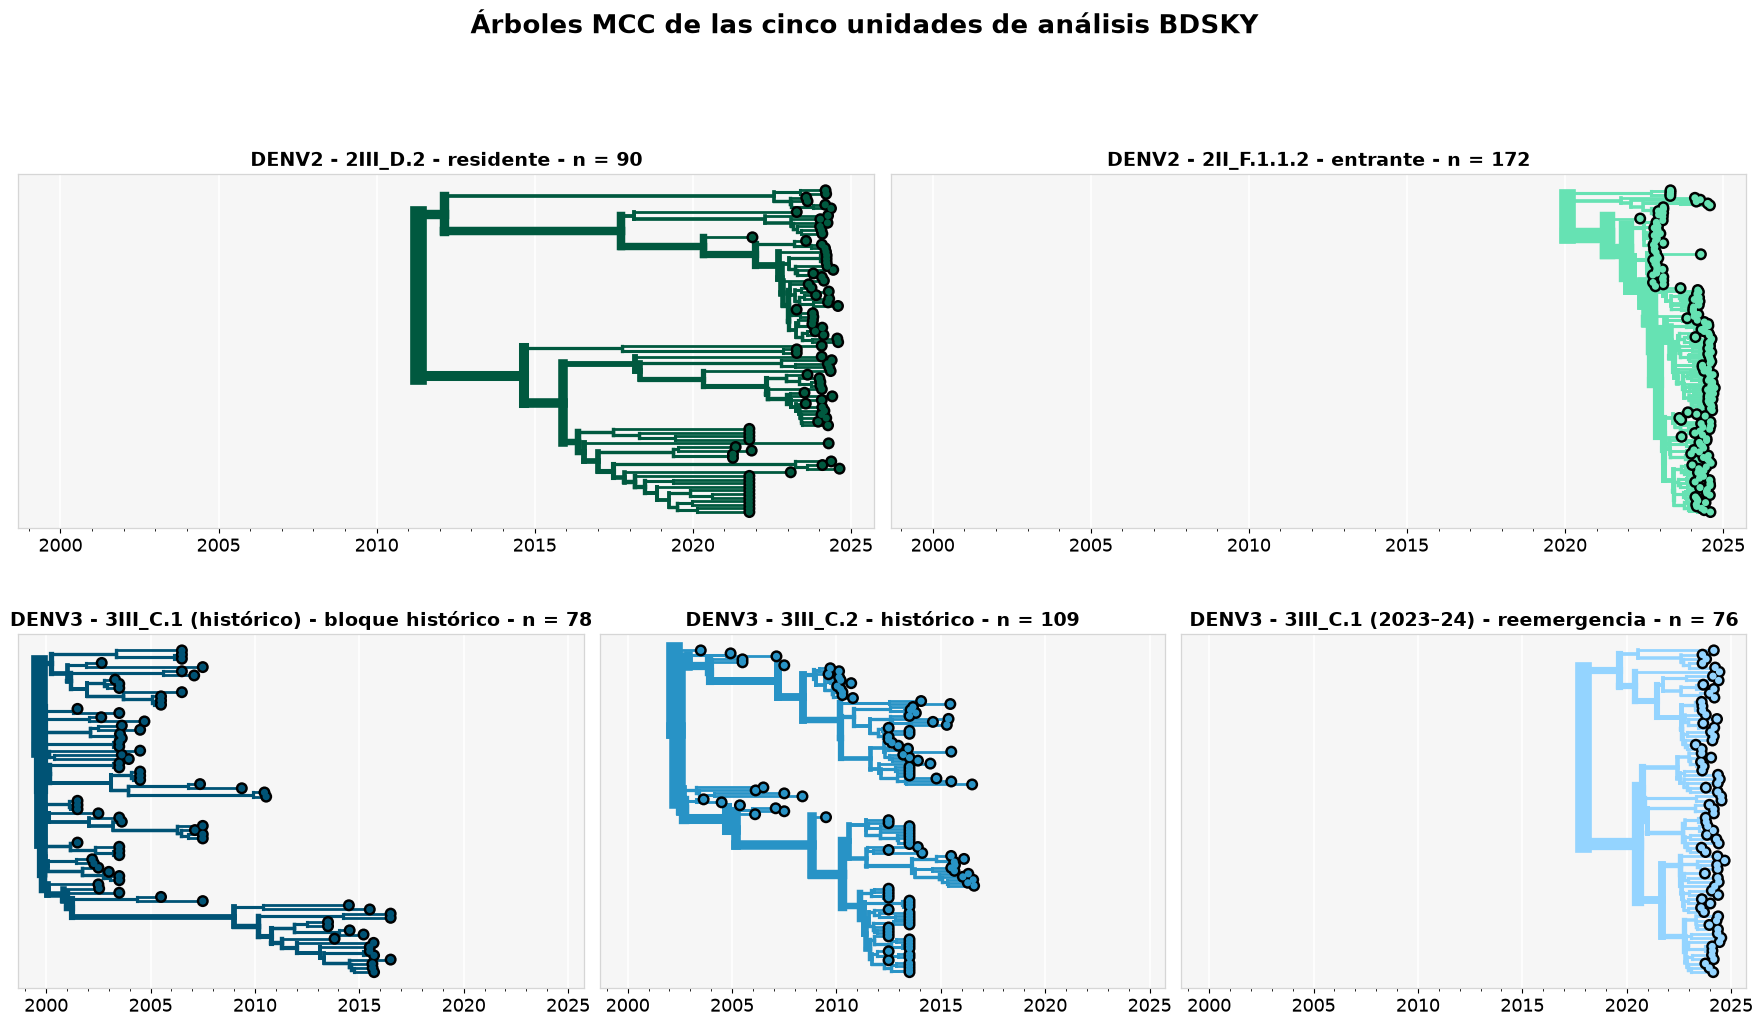

2III_D.2               DENV-2 2III  n= 90  raíz 2011.32  puntas 2021.27–2024.64  #00593f
2II_F.1.1.2            DENV-2 2II   n=172  raíz 2020.07  puntas 2022.38–2024.74  #66e2b3
3III_C.1 (histórico)   DENV-3 3III  n= 78  raíz 1999.67  puntas 2001.50–2016.50  #005375
3III_C.2               DENV-3 3III  n=109  raíz 2002.20  puntas 2003.50–2016.59  #2893c6
3III_C.1 (2023–24)     DENV-3 3III  n= 76  raíz 2017.92  puntas 2023.31–2024.69  #94d4ff

Figura guardada en: ../figures/arboles_mcc_linajes.png


In [80]:
# ─── cargar los cinco arboles
analisis = [dict(a) for a in LINAJES]
for a in analisis:
    ll = load_beast_tree(LIN_MCC.format(a["tag"]), DATES_FILES[a["sero"]])
    puntas = [k.absoluteTime for k in ll.Objects if k.branchType == "leaf"]
    a.update(ll=ll, n=len(puntas), primera=min(puntas), ultima=max(puntas),
             raiz=min(k.absoluteTime for k in ll.Objects))


# ─── figura: una fila por serotipo, eje temporal comun a los cinco paneles
coma = lambda v: ("%.1f" % v).replace(".", ",")
x0 = min(a["raiz"] for a in analisis)
x1 = max(a["ultima"] for a in analisis)
pad = 0.04 * (x1 - x0)
filas = sorted({a["sero"] for a in analisis})

fig = plt.figure(figsize=(18, 11), facecolor="w")
gs = gridspec.GridSpec(len(filas), 6, hspace=0.30, wspace=0.06)

for r, sero in enumerate(filas):
    grupo = [a for a in analisis if a["sero"] == sero]
    ancho = 6 // len(grupo)
    for c, a in enumerate(grupo):
        ax = fig.add_subplot(gs[r, c * ancho:(c + 1) * ancho])
        ll, col, L = a["ll"], a["color"], a["n"]

        # grosor de rama proporcional al numero de hojas descendientes
        b_func = lambda k: (2 + 10.0 * len(k.leaves) / L
                            if k.branchType == "node" else 2)
        x_abs = lambda k: k.absoluteTime
        ll.plot_tree(ax, xCoordinateFxn=x_abs, widthFxn=b_func,
                     colourFxn=lambda k, col=col: col, zorder=20000)
        ll.plot_points(ax, xCoordinateFxn=x_abs, pointSize=26,
                       colourFxn=lambda k, col=col: col, zorder=20002)

        ax.set_facecolor("#f6f6f6")
        for s in ax.spines.values():
            s.set_visible(True)
            s.set_color("#d6d6d6")
            s.set_linewidth(0.9)
        ax.set_axisbelow(True)
        ax.grid(axis="x", ls="-", color="white", lw=1.2, alpha=1.0)
        ax.tick_params(axis="y", size=0)
        ax.tick_params(axis="x", labelsize=13)
        ax.set_yticklabels([])
        ax.set_xlim(x0 - pad, x1 + pad)
        ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(5))
        ax.xaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(1))
        ax.set_title("DENV%s - %s - %s - n = %d"
                     % (a["sero"], a["etiq"], a["papel"], a["n"]),
                     fontsize=14, fontweight="bold")

fig.suptitle("Árboles MCC de las cinco unidades de análisis BDSKY",
             fontsize=19, fontweight="bold", y=0.99)

fig.subplots_adjust(left=0.03, right=0.99, top=0.84, bottom=0.10)
fig.savefig(FIG_LINAJES, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

for a in analisis:
    print("%-22s DENV-%d %-5s n=%3d  raíz %.2f  puntas %.2f–%.2f  %s"
          % (a["etiq"], a["sero"], a["gen"], a["n"], a["raiz"],
             a["primera"], a["ultima"], a["color"]))
print("\nFigura guardada en:", FIG_LINAJES)


## Relacion arbol MCC - mapa antigenico

Un panel por unidad de analisis BDSKY: el arbol MCC del linaje arriba y, abajo, la region del mapa antigenico que ocupan sus secuencias proyectadas. Los demas linajes del serotipo van con su propio color y el resto de la nube del serotipo en gris.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


2II_F.1.1.2            172 puntas | 172 con coordenadas | otros linajes 2III_D.2 87 | sin análisis 208
3III_C.1 (2023–24)      76 puntas |  76 con coordenadas | otros linajes 3III_C.1 (histórico) 77, 3III_C.2 108 | sin análisis   0


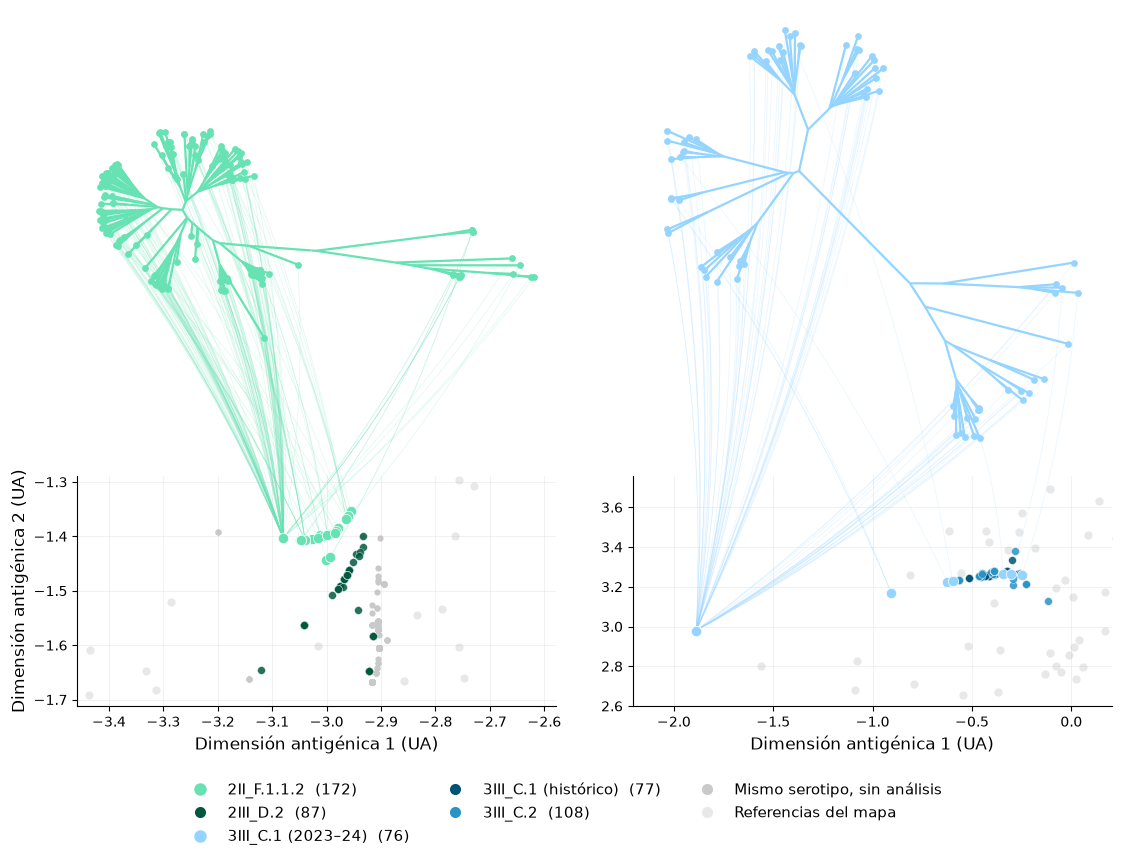

guardada: ../figures/arbol_mapa_entrantes.png


In [94]:
# Un panel por linaje: el árbol MCC de la unidad de análisis BDSKY y la región
# del mapa antigénico que ocupan sus secuencias proyectadas.
#
# Antes esta figura se hacía por serotipo, con los árboles de resources/BEAST/old.
# Ahora usa los cinco árboles de linaje, que son los que sostienen el capítulo
# de filodinámica. Consecuencia a declarar: DENV-1 y DENV-4 no tienen análisis
# por linaje, así que desaparecen de esta figura.
#
# En cada panel los demás linajes del mismo serotipo van con su propio color,
# no en gris: en el panel de 2III_D.2 se ve dónde cae 2II_F.1.1.2. El gris queda
# para las secuencias del serotipo que no pertenecen a ninguna unidad de
# análisis. La ventana del mapa es común a todos los paneles de un serotipo,
# así que los paneles se pueden comparar entre sí.

sys.setrecursionlimit(10000)

GRIS_REF = "#e8e8e8"      # referencias del mapa experimental
GRIS_SERO = "#c9c9c9"     # secuencias del serotipo fuera de todo análisis

SPAN_MIN = 0.5        # amplitud mínima de la ventana, solo para que no haga zoom
                      # absurdo cuando las proyecciones de un linaje colapsan
                      # en un punto
PAD = 0.18


def unrooted_layout(ll, rotate=0.2):
    """Coloca cada nodo del árbol de baltic en el plano (equal-angle).
    Devuelve edges: [(padre, hijo, (x0,y0), (x1,y1))] y pos: id(nodo) -> (x,y)."""
    n_leaves = {}

    def count(k):
        n_leaves[id(k)] = 1 if k.branchType == "leaf" else sum(count(c) for c in k.children)
        return n_leaves[id(k)]
    count(ll.root)

    pos, edges = {}, []

    def rec(k, x, y, a0, a1):
        pos[id(k)] = (x, y)
        if k.branchType == "leaf":
            return
        ang = a0
        for ch in sorted(k.children, key=lambda c: -n_leaves[id(c)]):
            span = (a1 - a0) * n_leaves[id(ch)] / n_leaves[id(k)]
            mid = ang + span / 2
            L = ch.length or 0.0
            cx, cy = x + L * np.cos(mid), y + L * np.sin(mid)
            edges.append((k, ch, (x, y), (cx, cy)))
            rec(ch, cx, cy, ang, ang + span)
            ang += span
    rec(ll.root, 0.0, 0.0, rotate, rotate + 2 * np.pi)
    return edges, pos


# --- los cinco árboles se cargan una sola vez: cada panel necesita saber qué
# puntas tienen los otros linajes de su serotipo
ARBOLES, PUNTAS = {}, {}
for _a in LINAJES:
    ARBOLES[_a["tag"]] = load_beast_tree(LIN_MCC.format(_a["tag"]),
                                         DATES_FILES[_a["sero"]])
    PUNTAS[_a["tag"]] = [k.name for k in ARBOLES[_a["tag"]].Objects
                         if k.branchType == "leaf"]


def ventana_serotipo(sero, projected_coordinates):
    """Encuadre común a todos los paneles de un serotipo: la nube de todas sus
    unidades de análisis juntas, más un margen."""
    proj = projected_coordinates[sero]
    nombres = sorted({n for a in LINAJES if a["sero"] == sero
                      for n in PUNTAS[a["tag"]] if n in proj.index})
    pts = proj.loc[nombres, ["X", "Y"]].values.astype(float)
    (x0, y0), (x1, y1) = pts.min(axis=0), pts.max(axis=0)
    w = max(x1 - x0, SPAN_MIN) * (1 + 2 * PAD)
    h = max(y1 - y0, 0.15 * (x1 - x0), SPAN_MIN * 0.3) * (1 + 2 * PAD)
    return (x0 + x1) / 2, (y0 + y1) / 2, w, h


VENTANAS = {s: ventana_serotipo(s, projected_coordinates)
            for s in sorted({a["sero"] for a in LINAJES})}


# ─────────── figura: los dos linajes entrantes, uno al lado del otro ───────────
#
# Dos columnas, una por entrante. Arriba el arbol MCC sin raiz; abajo la region
# del mapa antigenico que ocupan sus secuencias proyectadas. Sin titulos: la
# identidad del linaje va dentro del panel del arbol, en su color.
#
# Las dos columnas comparten forma. Los arboles van con aspecto igual dentro de
# cajas identicas, y las dos ventanas del mapa se EXPANDEN —nunca se recortan—
# hasta compartir la misma relacion ancho/alto, de modo que los dos mapas ocupan
# rectangulos iguales sin deformar las distancias: las dos dimensiones del mapa
# estan en la misma unidad (1 UA = una dilucion doble del titulo) y el aspecto
# tiene que seguir siendo igual.

ENTRANTES = ["DENV2_2II_F1112", "DENV3_3III_C1_2023"]
POR_TAG = {a["tag"]: a for a in LINAJES}

ANCHO_COL = 5.2          # pulgadas utiles de cada columna
ALTO_ARBOL = 4.6
RATIO_MAPA = 2.2         # ancho/alto de la caja del mapa, igual en las dos


def ventanas_armonicas(tags, r=RATIO_MAPA):
    """{tag: (cx, cy, w, h)} expandidas a la relacion ancho/alto de la caja.

    Las nubes son cintas muy planas (ancho/alto de 4 a 5). Dibujarlas en una
    caja con esa forma daria dos tiras ilegibles bajo los arboles, y recortar
    la ventana perderia puntos, asi que se EXPANDE la dimension que falte
    hasta r. El aspecto sigue siendo igual, que es obligatorio: las dos
    dimensiones del mapa estan en la misma unidad.
    """
    fuera = {}
    for t in tags:
        cx, cy, w, h = VENTANAS[POR_TAG[t]["sero"]]
        w, h = (h * r, h) if w / h < r else (w, w / r)
        fuera[t] = (cx, cy, w, h)
    return fuera, r


def panel_entrante(ax_tree, ax_map, a, ventana, projected_coordinates,
                   ref_xy=None, connect=True, rotate=0.2):
    """Dibuja una columna y devuelve sus entradas de leyenda."""
    col = a["color"]
    proj = projected_coordinates[a["sero"]]
    ll = ARBOLES[a["tag"]]
    tips = [k for k in ll.Objects if k.branchType == "leaf"]
    con_coord = [k.name for k in tips if k.name in proj.index]
    xy = {t: proj.loc[t, ["X", "Y"]].values.astype(float) for t in con_coord}
    sin_coord = len(tips) - len(con_coord)

    otros = [o for o in LINAJES
             if o["sero"] == a["sero"] and o["tag"] != a["tag"]]
    nom_otros = {o["tag"]: [n for n in PUNTAS[o["tag"]]
                            if n in proj.index and n not in xy] for o in otros}
    analizadas = set(con_coord) | {n for v in nom_otros.values() for n in v}
    resto = proj.drop(index=[n for n in analizadas if n in proj.index])

    cx, cy, w, h = ventana
    ax_map.set_xlim(cx - w / 2, cx + w / 2)
    ax_map.set_ylim(cy - h / 2, cy + h / 2)
    ax_map.set_aspect("equal", adjustable="datalim")

    if ref_xy is not None:
        ax_map.scatter(ref_xy.coord1, ref_xy.coord2, s=24, c=GRIS_REF, zorder=0)
    if len(resto):
        ax_map.scatter(resto["X"], resto["Y"], s=20, c=GRIS_SERO,
                       linewidths=0, zorder=1)
    for o in otros:
        ns = nom_otros[o["tag"]]
        if ns:
            p = proj.loc[ns, ["X", "Y"]].values.astype(float)
            ax_map.scatter(p[:, 0], p[:, 1], s=32, c=o["color"], alpha=0.85,
                           edgecolor="white", linewidths=0.3, zorder=2)

    edges, pos = unrooted_layout(ll, rotate)
    ax_tree.add_collection(LineCollection([[e[2], e[3]] for e in edges],
                                          colors=col, linewidths=1.6, zorder=10))
    leaf_xy = {k.name: pos[id(k)] for k in tips}
    ax_tree.scatter([leaf_xy[n][0] for n in con_coord],
                    [leaf_xy[n][1] for n in con_coord],
                    c=col, s=24, zorder=20, linewidths=0)
    if sin_coord:
        falta = [k.name for k in tips if k.name not in proj.index]
        ax_tree.scatter([leaf_xy[n][0] for n in falta],
                        [leaf_xy[n][1] for n in falta],
                        c="none", edgecolor=col, s=24, zorder=20, linewidths=0.8)
    ax_tree.autoscale_view()
    ax_tree.set_aspect("equal", adjustable="datalim")
    for sp in ax_tree.spines.values():
        sp.set_visible(False)
    ax_tree.set_xticks([]); ax_tree.set_yticks([])
    ax_tree.set_facecolor("none")
    ax_tree.set_zorder(4)

    pts = np.array([xy[n] for n in con_coord])
    ax_map.scatter(pts[:, 0], pts[:, 1], c=col, edgecolor="white",
                   linewidths=0.5, s=55, zorder=3)
    if connect:
        for n in con_coord:
            ax_map.add_artist(ConnectionPatch(
                xyA=tuple(xy[n]), coordsA=ax_map.transData,
                xyB=tuple(leaf_xy[n]), coordsB=ax_tree.transData,
                color=col, linewidth=0.5, alpha=0.22,
                connectionstyle="arc3,rad=0.06", zorder=0))

    ax_map.set_xlabel("Dimensión antigénica 1 (UA)", fontsize=12)
    ax_map.tick_params(axis="both", labelsize=10)
    for sp in ("right", "top"):
        ax_map.spines[sp].set_visible(False)
    ax_map.grid(alpha=0.2, lw=0.6)

    punto = lambda c, lab, ms=10: Line2D([0], [0], marker="o", color="w",
                                         markersize=ms, markerfacecolor=c,
                                         label=lab)
    hs = [punto(col, f"{a['etiq']}  ({len(con_coord)})")]
    if sin_coord:
        hs.append(Line2D([0], [0], marker="o", color="w", markersize=10,
                         markerfacecolor="none", markeredgecolor=col,
                         label=f"{a['etiq']}, sin coordenadas  ({sin_coord})"))
    for o in otros:
        if nom_otros[o["tag"]]:
            hs.append(punto(o["color"],
                            f"{o['etiq']}  ({len(nom_otros[o['tag']])})", 9))
    print(f"{a['etiq']:<22} {len(tips):3d} puntas | {len(con_coord):3d} con "
          f"coordenadas | otros linajes "
          + ", ".join(f"{o['etiq']} {len(nom_otros[o['tag']])}" for o in otros)
          + f" | sin análisis {len(resto):3d}")
    return hs


def figura_entrantes(projected_coordinates, ref_xy=None,
                     out="../figures/arbol_mapa_entrantes.png"):
    vent, r = ventanas_armonicas(ENTRANTES)
    alto_mapa = ANCHO_COL / r
    fig_w = 2 * ANCHO_COL / 0.92
    fig_h = (ALTO_ARBOL + alto_mapa) / 0.80

    fig = plt.figure(figsize=(fig_w, fig_h), facecolor="w")
    gs = gridspec.GridSpec(2, 2, height_ratios=[ALTO_ARBOL, alto_mapa],
                           hspace=0.05, wspace=0.16,
                           left=0.07, right=0.985, top=0.97, bottom=0.17)
    handles = []
    for c, tag in enumerate(ENTRANTES):
        ax_map = fig.add_subplot(gs[1, c])
        ax_tree = fig.add_subplot(gs[0, c])
        handles += panel_entrante(ax_tree, ax_map, POR_TAG[tag], vent[tag],
                                  projected_coordinates, ref_xy=ref_xy)
        if c == 0:
            ax_map.set_ylabel("Dimensión antigénica 2 (UA)", fontsize=12)

    punto = lambda c, lab: Line2D([0], [0], marker="o", color="w",
                                  markersize=9, markerfacecolor=c, label=lab)
    handles.append(punto(GRIS_SERO, "Mismo serotipo, sin análisis"))
    if ref_xy is not None:
        handles.append(punto(GRIS_REF, "Referencias del mapa"))
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
               fontsize=11, bbox_to_anchor=(0.5, -0.005))
    fig.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("guardada:", out)


figura_entrantes(projected_coordinates, ref_xy=mapa_ag[mapa_ag.type == "AG"])


## Matrices de distancia patristica y prueba de Mantel

Por unidad de analisis BDSKY, no por serotipo.


In [48]:
# Matrices de distancia patrística, una por unidad de análisis BDSKY.
# Antes se calculaban sobre los árboles por serotipo; ahora sobre los cinco
# árboles de linaje, que son los que sostienen el capítulo de filodinámica.

def patristic_matrix(ll):
    """Distancias patrísticas entre las puntas de un árbol de baltic.

    d(a,b) = h(a) + h(b) - 2*h(MRCA), con h la suma de longitudes de rama
    desde la raíz. En un árbol temporal de BEAST la unidad son años.

    Se arma de una vez con la matriz de ancestros A (puntas x nodos):
    h = A·L da la altura de cada punta y (A*L)·Aᵀ el tramo de camino que
    comparten los dos, así no hace falta recorrer el árbol por cada par.
    """
    objs = ll.Objects
    pos = {id(o): i for i, o in enumerate(objs)}
    L = np.array([o.length for o in objs], dtype=float)

    tips = [o for o in objs if o.branchType == "leaf"]
    A = np.zeros((len(tips), len(objs)), dtype=float)
    for i, t in enumerate(tips):
        n = t
        while n is not None and id(n) in pos:
            A[i, pos[id(n)]] = 1.0
            n = n.parent

    h = A @ L
    compartido = (A * L) @ A.T
    D = h[:, None] + h[None, :] - 2.0 * compartido
    np.fill_diagonal(D, 0.0)
    D = np.maximum(D, 0.0)          # limpia el -1e-15 del redondeo

    nombres = [t.name for t in tips]
    return pd.DataFrame(D, index=nombres, columns=nombres)


patristic = {}
for a in LINAJES:
    ll = load_beast_tree(LIN_MCC.format(a["tag"]), DATES_FILES[a["sero"]])
    M = patristic[a["tag"]] = patristic_matrix(ll)

    filename = PATRISTIC_FILE.format(tag=a["tag"])
    M.to_csv(filename, index=True)

    triu = M.values[np.triu_indices(len(M), k=1)]
    print(f"{a['etiq']:<22} {M.shape[0]:3d} puntas | mediana {np.median(triu):5.2f} "
          f"años | max {triu.max():5.2f} años -> {filename}")


2III_D.2                90 puntas | mediana 22.90 años | max 26.59 años -> ../output/patristic_MCC_DENV2_2III_D2.csv
2II_F.1.1.2            172 puntas | mediana  3.12 años | max  9.19 años -> ../output/patristic_MCC_DENV2_2II_F1112.csv
3III_C.1 (histórico)    78 puntas | mediana 11.41 años | max 27.49 años -> ../output/patristic_MCC_DENV3_3III_C1_hist.csv
3III_C.2               109 puntas | mediana 13.23 años | max 28.33 años -> ../output/patristic_MCC_DENV3_3III_C2.csv
3III_C.1 (2023–24)      76 puntas | mediana  7.64 años | max 13.29 años -> ../output/patristic_MCC_DENV3_3III_C1_2023.csv


2III_D.2                87 secuencias en 18 coordenadas distintas |  3741 pares, 17.6 % a distancia 0 | patrística 0.12–26.59 años | Mantel spearman: r = +0.606, p = 0.0010
2II_F.1.1.2            172 secuencias en 18 coordenadas distintas | 14706 pares, 57.7 % a distancia 0 | patrística 0.06–9.19 años | Mantel spearman: r = +0.077, p = 0.0680
3III_C.1 (histórico)    77 secuencias en 13 coordenadas distintas |  2926 pares, 29.8 % a distancia 0 | patrística 0.56–27.49 años | Mantel spearman: r = +0.130, p = 0.0020
3III_C.2               108 secuencias en 16 coordenadas distintas |  5778 pares, 22.9 % a distancia 0 | patrística 0.15–28.33 años | Mantel spearman: r = +0.297, p = 0.0010
3III_C.1 (2023–24)      76 secuencias en  7 coordenadas distintas |  2850 pares, 80.0 % a distancia 0 | patrística 0.59–13.29 años | Mantel spearman: r = +0.110, p = 0.0510


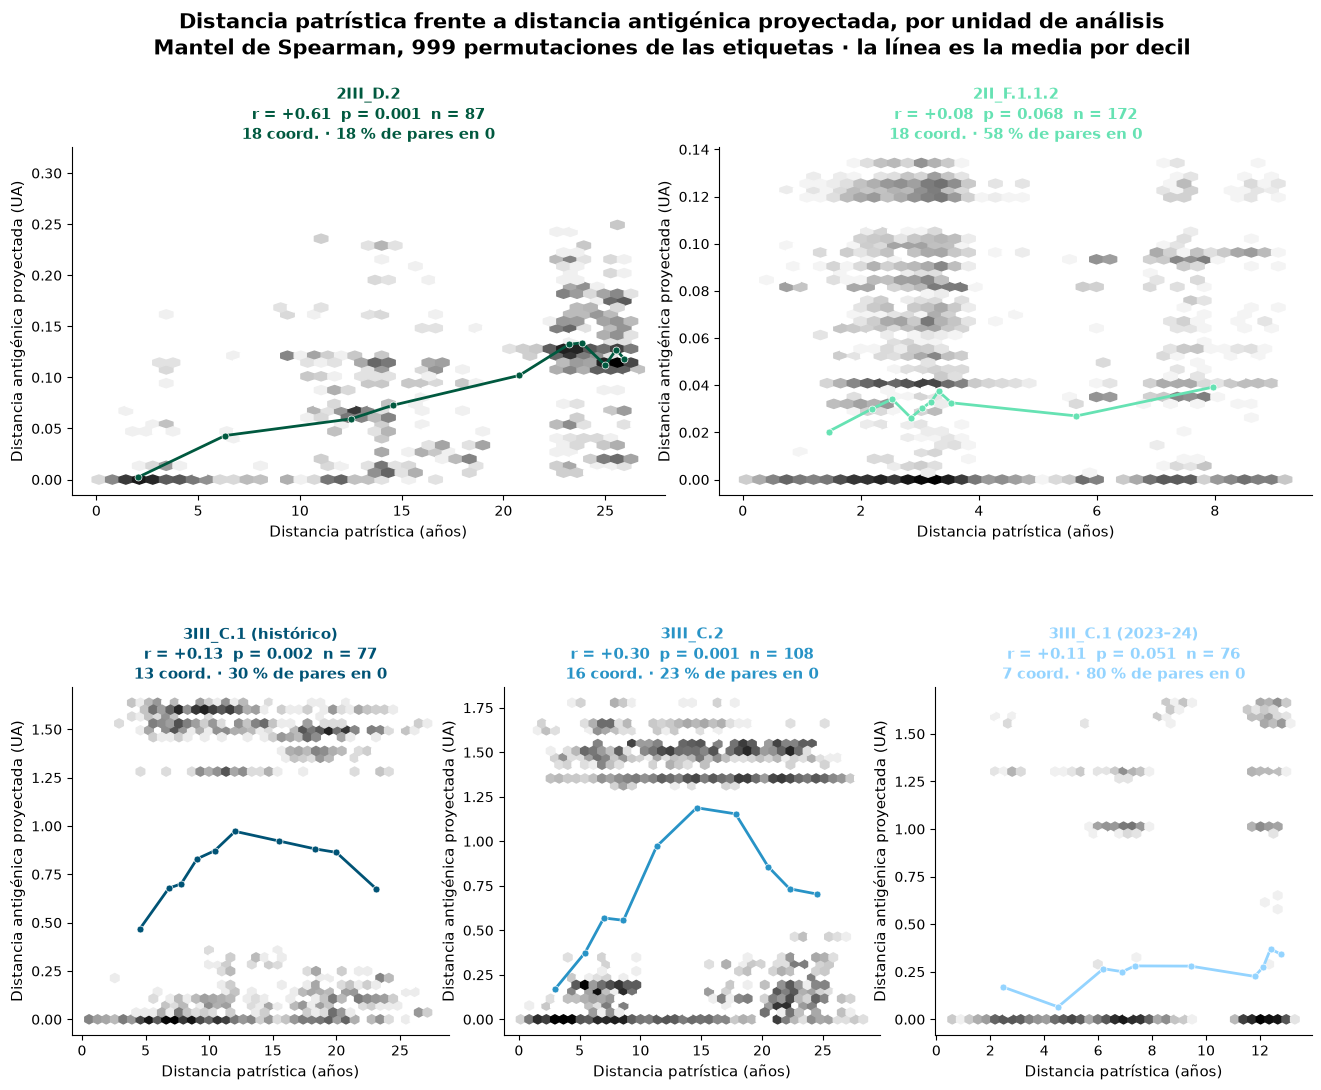


              linaje  serotipo  n_puntas  n_coord  n_pares  frac_cero  pat_min  pat_max      r     p   metodo
            2III_D.2         2        87       18     3741     0.1756   0.1236  26.5942 0.6062 0.001 spearman
         2II_F.1.1.2         2       172       18    14706     0.5770   0.0588   9.1884 0.0770 0.068 spearman
3III_C.1 (histórico)         3        77       13     2926     0.2980   0.5578  27.4904 0.1298 0.002 spearman
            3III_C.2         3       108       16     5778     0.2295   0.1457  28.3253 0.2971 0.001 spearman
  3III_C.1 (2023–24)         3        76        7     2850     0.8004   0.5889  13.2926 0.1095 0.051 spearman


In [49]:
# ───────────── Prueba de Mantel ─────────────
def mantel(A, B, method="spearman", perms=999, seed=0):
    """Correlacion entre dos matrices de distancias y valor p por permutacion de las etiquetas
    (las distancias por pares no son independientes, asi que un p de Pearson/Spearman seria enganoso).

    Para Spearman se rangea una sola vez la matriz completa: permutar filas y columnas
    a la vez no cambia el multiconjunto de distancias, asi que los rangos se conservan
    y no hace falta volver a rangear en cada permutacion.
    """
    n = A.shape[0]
    iu = np.triu_indices(n, 1)

    if method == "spearman":
        A = _rank_matrix(A)
        B = _rank_matrix(B)
    a = A[iu]
    r_obs = np.corrcoef(a, B[iu])[0, 1]

    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(perms):
        p = rng.permutation(n)
        r = np.corrcoef(a, B[np.ix_(p, p)][iu])[0, 1]
        count += (r >= r_obs - 1e-12)
    return r_obs, (count + 1) / (perms + 1)       # prueba de una cola: asociacion positiva


def _rank_matrix(M):
    """Reemplaza cada distancia por su rango entre todos los pares, conservando la simetria."""
    n = M.shape[0]
    iu = np.triu_indices(n, 1)
    R = np.zeros_like(M, dtype=float)
    R[iu] = rankdata(M[iu])
    return R + R.T


# ───────────── Análisis por linaje ─────────────
#
# Dos avisos sobre lo que esta prueba puede y no puede decir dentro de un linaje.
#
# 1. La coordenada antigénica se proyecta a partir de la secuencia del gen E, y
#    la distancia patrística también depende de esa secuencia, así que parte de
#    la correlación es estructural y no evidencia de que la divergencia genética
#    prediga la antigénica. Entre serotipos el sesgo quedaba diluido por un rango
#    de decenas de años; dentro de un linaje el rango se estrecha y pesa más.
#
# 2. La proyección casi no resuelve dentro de un linaje: las 172 secuencias de
#    2II_F.1.1.2 caen en 18 coordenadas distintas y las 76 de 3III_C.1 (2023–24)
#    en 7, de modo que el 58 % y el 80 % de los pares están a distancia
#    exactamente 0. La variable de respuesta no es continua sino un puñado de
#    posiciones con muchos empates, así que el r mide si esos pocos grupos se
#    separan, no una relación continua. Cada panel declara cuántas coordenadas
#    distintas hay y qué fracción de pares está en 0.

def mantel_panel(a, P, B, ylabel, extra="", perms=999, method="spearman", ax=None):
    """Mantel entre dos matrices de distancia del mismo linaje, y su panel.

    P es la patrística y B la otra. `extra` es la tercera línea del título, que
    cada figura rellena con sus propios diagnósticos.
    """
    r, p = mantel(P, B, method=method, perms=perms)
    iu = np.triu_indices(P.shape[0], 1)

    if ax is not None:
        ax.hexbin(P[iu], B[iu], gridsize=40, bins="log", cmap="Greys", mincnt=1)
        # Media, no mediana, de la segunda distancia por decil de la patrística:
        # con muchos empates la mediana salta de una moda a otra y dibuja un
        # escalón que no está en los datos.
        qs = np.quantile(P[iu], np.linspace(0, 1, 11))
        cen, prom = [], []
        for lo, hi in zip(qs[:-1], qs[1:]):
            m = (P[iu] >= lo) & (P[iu] <= hi)
            if m.any():
                cen.append(P[iu][m].mean())
                prom.append(B[iu][m].mean())
        ax.plot(cen, prom, "-o", color=a["color"], ms=5, lw=2,
                markeredgecolor="white", markeredgewidth=0.5)
        ax.set_xlabel("Distancia patrística (años)", fontsize=11)
        ax.set_ylabel(ylabel, fontsize=11)
        ax.set_title(f"{a['etiq']}\n"
                     f"r = {r:+.2f}  p = {p:.3g}  n = {P.shape[0]}"
                     + (f"\n{extra}" if extra else ""),
                     fontweight="bold", fontsize=11, color=a["color"],
                     linespacing=1.3)
        ax.tick_params(labelsize=10)
        for sp in ("right", "top"):
            ax.spines[sp].set_visible(False)
    return r, p, iu


def rejilla_linajes(alto_por_fila=6.0):
    """Una fila por serotipo, con tantos paneles como linajes tenga."""
    filas = sorted({a["sero"] for a in LINAJES})
    fig = plt.figure(figsize=(16, alto_por_fila * len(filas)), facecolor="w")
    gs = gridspec.GridSpec(len(filas), 6, hspace=0.55, wspace=0.34)
    ejes = {}
    for r_, sero in enumerate(filas):
        grupo = [a for a in LINAJES if a["sero"] == sero]
        ancho = 6 // len(grupo)
        for c_, a in enumerate(grupo):
            ejes[a["tag"]] = fig.add_subplot(gs[r_, c_ * ancho:(c_ + 1) * ancho])
    return fig, ejes, len(filas)


def patristic_vs_antigenic(a, patristic, projected_coordinates,
                           perms=999, method="spearman", ax=None):
    """Usa las matrices patrísticas ya calculadas y las coordenadas proyectadas."""
    P_df = patristic[a["tag"]]
    proj = projected_coordinates[a["sero"]]

    comunes = [n for n in P_df.index if n in proj.index]
    if len(comunes) < 3:
        raise ValueError(f"{a['etiq']}: muy pocas hojas emparejadas")

    P = P_df.loc[comunes, comunes].to_numpy(dtype=float)
    xy = proj.loc[comunes, ["X", "Y"]].to_numpy(dtype=float)
    A = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(-1))   # distancia antigenica proyectada

    n_coord = len({tuple(np.round(v, 6)) for v in xy})   # posiciones distintas
    iu0 = np.triu_indices(len(comunes), 1)
    frac_cero = float((A[iu0] < 1e-9).mean())            # pares antigénicamente iguales

    r, p, iu = mantel_panel(
        a, P, A, "Distancia antigénica proyectada (UA)",
        extra=f"{n_coord} coord. · {100*frac_cero:.0f} % de pares en 0",
        perms=perms, method=method, ax=ax)

    print(f"{a['etiq']:<22} {len(comunes):3d} secuencias en {n_coord:2d} "
          f"coordenadas distintas | {len(iu[0]):5d} pares, {100*frac_cero:4.1f} % "
          f"a distancia 0 | patrística {P[iu].min():.2f}–{P[iu].max():.2f} años "
          f"| Mantel {method}: r = {r:+.3f}, p = {p:.4f}")

    return dict(linaje=a["etiq"], serotipo=a["sero"], n_puntas=len(comunes),
                n_coord=n_coord, n_pares=len(iu[0]), frac_cero=frac_cero,
                pat_min=P[iu].min(), pat_max=P[iu].max(),
                r=r, p=p, metodo=method)

# ───────────── Uso: una fila por serotipo ─────────────
fig, ejes, n_filas = rejilla_linajes()
res = [patristic_vs_antigenic(a, patristic, projected_coordinates,
                              ax=ejes[a["tag"]]) for a in LINAJES]

fig.suptitle("Distancia patrística frente a distancia antigénica proyectada, "
             "por unidad de análisis\n"
             "Mantel de Spearman, 999 permutaciones de las etiquetas · "
             "la línea es la media por decil",
             fontsize=15, fontweight="bold", y=0.965)
fig.subplots_adjust(top=0.85 if n_filas > 1 else 0.74)
fig.savefig("../figures/patristica_vs_antigenica.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print()
print(pd.DataFrame(res).round(4).to_string(index=False))


### Distancia epitopica de Grantham contra distancia patristica

La misma comparacion, cambiando la coordenada del mapa antigenico por la
distancia p-all-epitope de Grantham entre las secuencias de aminoacidos del
gen E.


DENV2: 467 secuencias de aminoácidos
DENV3: 261 secuencias de aminoácidos
   2III_D.2: 3 puntas sin secuencia de aminoácidos
   3III_C.1 (histórico): 1 puntas sin secuencia de aminoácidos
   3III_C.2: 1 puntas sin secuencia de aminoácidos
2III_D.2                87 secuencias |  3741 pares, 17.6 % idénticos en los epítopos | Grantham 0.000–0.220 | Mantel spearman: r = +0.633, p = 0.0010
2II_F.1.1.2            172 secuencias | 14706 pares, 57.7 % idénticos en los epítopos | Grantham 0.000–0.193 | Mantel spearman: r = +0.081, p = 0.0750
3III_C.1 (histórico)    77 secuencias |  2926 pares, 29.8 % idénticos en los epítopos | Grantham 0.000–0.146 | Mantel spearman: r = +0.231, p = 0.0010
3III_C.2               108 secuencias |  5778 pares, 22.9 % idénticos en los epítopos | Grantham 0.000–0.253 | Mantel spearman: r = +0.508, p = 0.0010
3III_C.1 (2023–24)      76 secuencias |  2850 pares, 80.0 % idénticos en los epítopos | Grantham 0.000–0.160 | Mantel spearman: r = +0.113, p = 0.0460


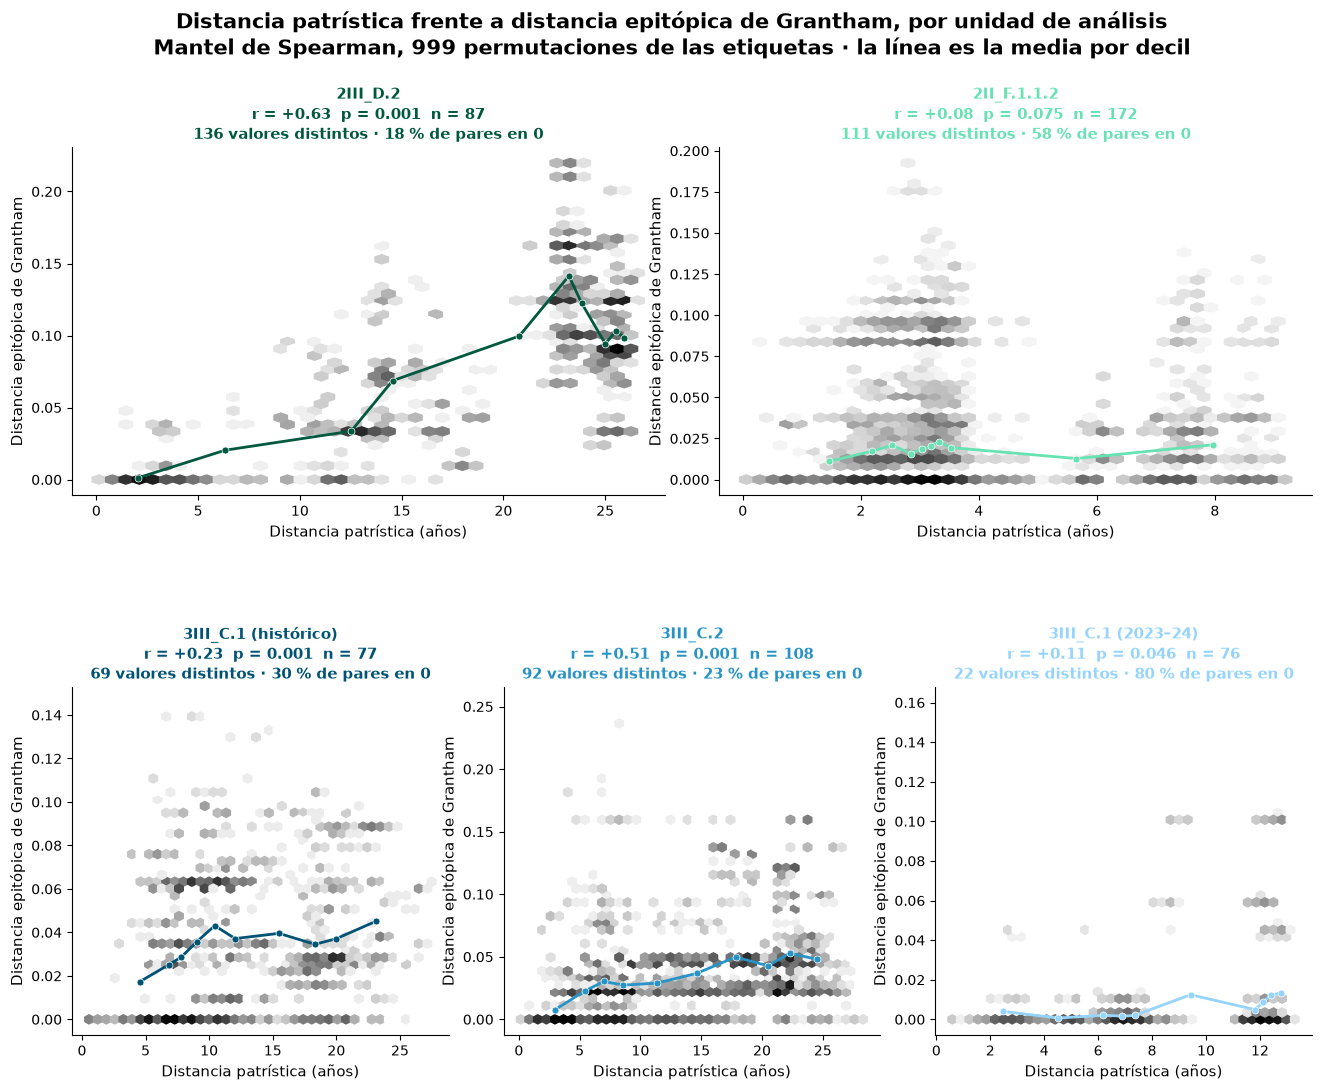


              linaje  serotipo  n_puntas  n_valores  n_pares  frac_cero  gran_min  gran_max      r     p   metodo
            2III_D.2         2        87        136     3741     0.1756       0.0    0.2198 0.6334 0.001 spearman
         2II_F.1.1.2         2       172        111    14706     0.5770       0.0    0.1926 0.0806 0.075 spearman
3III_C.1 (histórico)         3        77         69     2926     0.2980       0.0    0.1456 0.2309 0.001 spearman
            3III_C.2         3       108         92     5778     0.2295       0.0    0.2530 0.5082 0.001 spearman
  3III_C.1 (2023–24)         3        76         22     2850     0.8004       0.0    0.1599 0.1131 0.046 spearman


In [50]:
# Distancia epitópica de Grantham dentro de cada linaje, contra la patrística.
#
# `output/distances_epitope_grantham_DENV<s>.csv` no sirve aquí: es colombianas
# contra las 385 referencias del mapa, no colombianas contra colombianas. La
# matriz dentro del conjunto se calcula con scripts/epitope_grantham.py, que
# repite las definiciones de DistancesCalculation.ipynb —matriz de Grantham,
# sitios epitópicos, numeración común DENV1/2/4 y la normalización de las
# ecuaciones 2 y 3— y trae una autoprueba que contrasta su versión vectorizada
# contra la implementación par a par.
#
# Aviso sobre lo que mide: la distancia epitópica y la patrística salen las dos
# de la misma secuencia del gen E, una de los aminoácidos en los sitios de
# epítopo y la otra de las sustituciones acumuladas en el tiempo. Un r alto es
# en buena parte aritmética, no un hallazgo; lo informativo es lo contrario,
# un linaje donde el reloj avanza y la distancia epitópica no.

sys.path.insert(0, "../scripts")
import epitope_grantham as eg
from Bio import SeqIO

AA_SEQS_COL_E = "../resources/colombia_data/AA_sequences/E_DENV{}_aa_E.fasta"

# secuencias de aminoácidos del gen E, por serotipo, sin los nodos internos
aa_col = {}
for _s in sorted({a["sero"] for a in LINAJES}):
    aa_col[_s] = {r.id: str(r.seq) for r in SeqIO.parse(AA_SEQS_COL_E.format(_s), "fasta")
                  if not r.id.startswith("NODE")}
    print(f"DENV{_s}: {len(aa_col[_s])} secuencias de aminoácidos")

grantham = {}
for a in LINAJES:
    P_df = patristic[a["tag"]]
    aa = aa_col[a["sero"]]
    comunes = [n for n in P_df.index if n in aa]
    if len(comunes) < len(P_df.index):
        print(f"   {a['etiq']}: {len(P_df.index) - len(comunes)} puntas sin "
              f"secuencia de aminoácidos")
    M = eg.matriz(comunes, [aa[n] for n in comunes])
    grantham[a["tag"]] = pd.DataFrame(M, index=comunes, columns=comunes)


def patristic_vs_grantham(a, patristic, grantham, perms=999, method="spearman",
                          ax=None):
    P_df, G_df = patristic[a["tag"]], grantham[a["tag"]]
    comunes = [n for n in P_df.index if n in G_df.index]
    P = P_df.loc[comunes, comunes].to_numpy(dtype=float)
    G = G_df.loc[comunes, comunes].to_numpy(dtype=float)

    iu0 = np.triu_indices(len(comunes), 1)
    n_val = len(np.unique(np.round(G[iu0], 6)))     # valores distintos de distancia
    frac_cero = float((G[iu0] < 1e-9).mean())       # pares idénticos en los epítopos

    r, p, iu = mantel_panel(
        a, P, G, "Distancia epitópica de Grantham",
        extra=f"{n_val} valores distintos · {100*frac_cero:.0f} % de pares en 0",
        perms=perms, method=method, ax=ax)

    print(f"{a['etiq']:<22} {len(comunes):3d} secuencias | {len(iu[0]):5d} pares, "
          f"{100*frac_cero:4.1f} % idénticos en los epítopos | Grantham "
          f"{G[iu].min():.3f}–{G[iu].max():.3f} | "
          f"Mantel {method}: r = {r:+.3f}, p = {p:.4f}")

    return dict(linaje=a["etiq"], serotipo=a["sero"], n_puntas=len(comunes),
                n_valores=n_val, n_pares=len(iu[0]), frac_cero=frac_cero,
                gran_min=G[iu].min(), gran_max=G[iu].max(),
                r=r, p=p, metodo=method)


fig, ejes, n_filas = rejilla_linajes()
res_g = [patristic_vs_grantham(a, patristic, grantham, ax=ejes[a["tag"]])
         for a in LINAJES]

fig.suptitle("Distancia patrística frente a distancia epitópica de Grantham, "
             "por unidad de análisis\n"
             "Mantel de Spearman, 999 permutaciones de las etiquetas · "
             "la línea es la media por decil",
             fontsize=15, fontweight="bold", y=0.965)
fig.subplots_adjust(top=0.85 if n_filas > 1 else 0.74)
fig.savefig("../figures/patristica_vs_grantham.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print()
print(pd.DataFrame(res_g).round(4).to_string(index=False))


## Analisis Re por unidad de analisis BDSKY

Dos variantes: un panel por linaje, y los linajes superpuestos por serotipo.


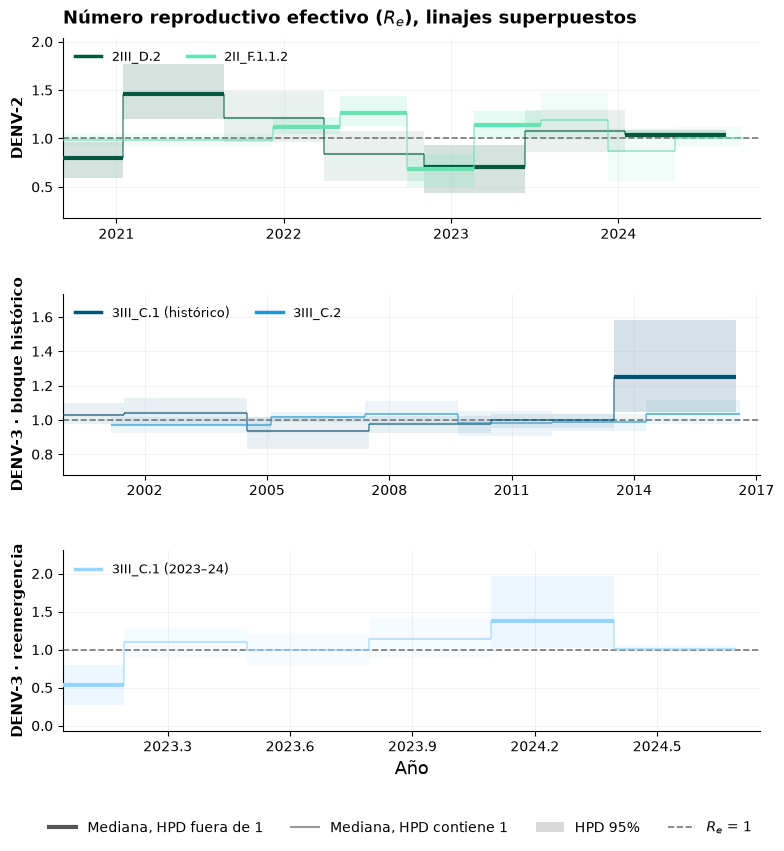

guardada: ../figures/bdsky_Re_por_serotipo.png

              linaje  intervalo      ini      fin  n  tallo  informativo  mediana    lo    hi  ancho_hpd
            2III_D.2          7 2009.156 2021.041  0   True         True    0.799 0.594 0.962      0.368
            2III_D.2          6 2021.041 2021.641  3  False         True    1.455 1.200 1.772      0.572
            2III_D.2          5 2021.641 2022.241 17  False        False    1.209 0.962 1.491      0.529
            2III_D.2          4 2022.241 2022.841  0  False        False    0.835 0.556 1.074      0.517
            2III_D.2          3 2022.841 2023.441  5  False         True    0.708 0.441 0.933      0.492
            2III_D.2          2 2023.441 2024.041 21  False        False    1.076 0.859 1.297      0.439
            2III_D.2          1 2024.041 2024.641 43  False         True    1.040 1.006 1.086      0.080
         2II_F.1.1.2          8 2017.424 2021.937  0   True        False    0.989 0.917 1.055      0.138
       

In [92]:
LIN_XML = "../resources/BEAST/lineage/BDSKY_{}.xml"
LIN_LOG = "../resources/BEAST/lineage/combined/BDSKY_{}_combined.log"

GRUPOS_RE = [
    ("DENV-2", ["DENV2_2III_D2", "DENV2_2II_F1112"]),
    ("DENV-3 · bloque histórico", ["DENV3_3III_C1_hist", "DENV3_3III_C2"]),
    ("DENV-3 · reemergencia", ["DENV3_3III_C1_2023"]),
]


def hpd(x, cred=0.95):
    """Intervalo de densidad posterior mas alta: el mas corto que contiene cred."""
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    k = int(np.floor(cred * n))
    i = int(np.argmin(x[k:] - x[:n - k]))
    return x[i], x[i + k]


def cambios_re(tag):
    """birthRateChangeTimes del XML, en años antes de la punta más reciente.

    Se leen del XML y no se escriben a mano para que la figura no pueda
    separarse del análisis que la produjo.
    """
    txt = open(LIN_XML.format(tag), encoding="utf-8").read()
    m = re.search(r"<birthRateChangeTimes[^>]*>([^<]*)</birthRateChangeTimes>", txt)
    if not m:
        raise ValueError(f"{tag}: no se encontró birthRateChangeTimes")
    return [float(v) for v in m.group(1).split()]


def fechas_linaje(a):
    """Fechas decimales de las puntas de ese linaje, del archivo del serotipo."""
    fechas = {}
    for linea in open(DATES_FILES[a["sero"]]):
        if linea.strip():
            nombre, f = linea.rstrip("\n").split("\t")
            fechas[nombre] = float(f)
    return np.array([fechas[n] for n in PUNTAS[a["tag"]] if n in fechas])


def re_skyline_linaje(a):
    """Mediana e HPD 95 % de Re por intervalo, situados en años calendario.

    Con reverseTimeArrays=true en birthRateChangeTimes los tiempos se cuentan
    hacia atrás desde la punta más reciente, y Re.1 es el intervalo MÁS
    RECIENTE, al revés que en el bdsky_plot.R original. El último intervalo no
    tiene borde: va desde el último tiempo de cambio hasta el origen, y es el
    tallo profundo, casi siempre sin muestras.
    """
    log = pd.read_csv(LIN_LOG.format(a["tag"]), sep="\t", comment="#")
    cols = sorted([c for c in log.columns if re.fullmatch(r"Re\.\d+", c)],
                  key=lambda c: int(c.split(".")[-1]))

    tiempos = cambios_re(a["tag"])
    if len(tiempos) != len(cols):
        raise ValueError(f"{a['etiq']}: {len(cols)} columnas Re y "
                         f"{len(tiempos)} tiempos de cambio")

    fechas = fechas_linaje(a)
    reciente = fechas.max()
    origen = log["origin"].median()

    filas = []
    for i, c in enumerate(cols):
        atras_fin = tiempos[i]                                  # borde reciente
        atras_ini = tiempos[i + 1] if i + 1 < len(tiempos) else origen
        ini, fin = reciente - atras_ini, reciente - atras_fin
        lo, hi = hpd(log[c].to_numpy())
        filas.append(dict(linaje=a["etiq"], tag=a["tag"], intervalo=i + 1,
                          ini=ini, fin=fin, centro=(ini + fin) / 2,
                          mediana=log[c].median(), lo=lo, hi=hi,
                          informativo=bool(lo > 1 or hi < 1),
                          tallo=(i + 1 == len(cols)),
                          n=int(((fechas >= ini) & (fechas < fin)).sum())))
    # de más antiguo a más reciente, para dibujar de izquierda a derecha
    return pd.DataFrame(filas).iloc[::-1].reset_index(drop=True)


def dibuja_skyline(ax, t, color, alpha_banda=0.22):
    """Escalón por intervalos, el tallo profundo incluido.

    Los que tienen el HPD fuera de 1 van en trazo grueso: son los únicos que
    dicen algo. El tallo va igual que los demás, sin trama: es el tramo entre
    el último tiempo de cambio y el origen, y no contiene secuencias.
    """
    for _, r in t.iterrows():
        inf = r.informativo
        ax.fill_between([r.ini, r.fin], [r.lo] * 2, [r.hi] * 2, color=color,
                        alpha=alpha_banda if inf else alpha_banda * 0.5, lw=0,
                        zorder=1)
        ax.hlines(r.mediana, r.ini, r.fin, color=color,
                  lw=3.0 if inf else 1.5, alpha=1.0 if inf else 0.6, zorder=3)
    prev = None
    for _, r in t.iterrows():          # conectores verticales del escalón
        if prev is not None:
            ax.vlines(r.ini, prev, r.mediana, color=color, lw=1.2,
                      alpha=0.6, zorder=3)
        prev = r.mediana


def ventana(t, margen_izq=0.10, margen_der=0.04):
    """Ventana de la parte con muestras, dejando asomar el tallo por la izquierda."""
    s = t[~t.tallo]
    ini, fin = s.ini.min(), s.fin.max()
    span = fin - ini
    return ini - margen_izq * span, fin + margen_der * span


def estilo_re(ax, color, etiqueta):
    ax.axhline(1.0, color="#777777", lw=1.2, ls="--", zorder=2)
    ax.set_ylabel(etiqueta, fontsize=11, fontweight="bold")
    ax.grid(alpha=0.18, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.20)
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(6, integer=True))


def leyenda_re(fig, y=-0.012):
    h = [Line2D([], [], color="#555555", lw=3, label="Mediana, HPD fuera de 1"),
         Line2D([], [], color="#555555", lw=1.5, alpha=0.6,
                label="Mediana, HPD contiene 1"),
         Patch(facecolor="#555555", alpha=0.22, label="HPD 95%"),
         Line2D([], [], color="#777777", lw=1.2, ls="--", label="$R_e$ = 1")]
    fig.legend(handles=h, loc="lower center", ncol=4, frameon=False, fontsize=10,
               bbox_to_anchor=(0.5, y))


# ─────────────────── los cinco skylines, una sola vez ───────────────────
skylines = {a["tag"]: re_skyline_linaje(a) for a in LINAJES}
por_tag = {a["tag"]: a for a in LINAJES}

def figura_agrupados(out="../figures/bdsky_Re_por_serotipo.png"):
    fig, axes = plt.subplots(len(GRUPOS_RE), 1, figsize=(9, 9),
                             gridspec_kw=dict(hspace=0.42))
    for ax, (titulo, tags) in zip(axes, GRUPOS_RE):
        ts, hs = [], []
        for tag in tags:
            a, t = por_tag[tag], skylines[tag]
            dibuja_skyline(ax, t, a["color"], alpha_banda=0.17)
            ts.append(t)
            hs.append(Line2D([], [], color=a["color"], lw=2.5,
                             label=f"{a['etiq']}"))
        color = lineage_shades(SERO_COLORS[por_tag[tags[0]]["sero"]], 3)[0]
        estilo_re(ax, color, titulo)
        x0 = min(ventana(t)[0] for t in ts)
        x1 = max(ventana(t)[1] for t in ts)
        ax.set_xlim(x0, x1)
        ax.legend(handles=hs, fontsize=9.5, frameon=False, loc="upper left",
                  ncol=len(hs))

    axes[-1].set_xlabel("Año", fontsize=13)
    axes[0].set_title("Número reproductivo efectivo ($R_e$), linajes "
                      "superpuestos",
                      loc="left", fontsize=13, fontweight="bold", pad=10)
    leyenda_re(fig, y=-0.02)
    fig.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("guardada:", out)


figura_agrupados()

tabla_re = pd.concat(skylines.values(), ignore_index=True)
tabla_re.to_csv("../output/bdsky_Re_intervalos.csv", index=False)
print()
print(tabla_re.assign(ancho_hpd=lambda d: d.hi - d.lo).round(3)
      [["linaje", "intervalo", "ini", "fin", "n", "tallo", "informativo",
        "mediana", "lo", "hi", "ancho_hpd"]].to_string(index=False))


## Diagnóstico de convergencia

Tabla mínima para el material suplementario: una fila por unidad de análisis
BDSKY con el ESS de `posterior`, `prior`, `likelihood` y la tasa del reloj, el
ESS de cada `Re` por intervalo, y el tMRCA con su HPD 95 %.


In [67]:
# Tabla de convergencia, una fila por unidad de análisis BDSKY.
#
# ESS por el algoritmo de Tracer (autocovarianza con denominador n−lag, parada
# por pares de rezagos consecutivos, ESS = n · γ(0) / varStat, MAX_LAG = 2000),
# calculado por FFT. Se calcula sobre todas las columnas y de ahí se extraen
# las de la tabla, para que `output/bdsky_ess_completo.csv` quede completo.
#
# El reloj es UCLD relajado: la tasa media es `ucldMean`, no hay `clockRate`.
# tMRCA = fecha de la punta más reciente del linaje − `Tree.height`.

MAX_LAG = 2000

COLS_TABLA = ["unidad", "n_puntas", "muestras", "ess_posterior", "ess_prior",
              "ess_likelihood", "ess_reloj", "ess_tmrca", "ess_log_rateCG"]


def _sumas_autocov(x):
    """Σ_j (x_j−m)(x_{j+lag}−m) para todo rezago, por FFT con relleno de ceros."""
    d = np.asarray(x, dtype=float)
    d = d - d.mean()
    nf = 1 << (2 * len(d) - 1).bit_length()
    f = np.fft.rfft(d, nf)
    return np.fft.irfft(f * np.conjugate(f), nf)[:len(d)]


def ess_tracer(x, max_lag=MAX_LAG):
    """ESS tal y como lo calcula Tracer. NaN si la traza es constante."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n < 10 or np.ptp(x) == 0:
        return np.nan
    m = min(n, max_lag)
    gamma = _sumas_autocov(x)[:m] / (n - np.arange(m))
    if gamma[0] <= 0:
        return np.nan
    var = gamma[0]
    for lag in range(2, m, 2):
        if gamma[lag - 1] + gamma[lag] <= 0:
            break
        var += 2.0 * (gamma[lag - 1] + gamma[lag])
    return n * gamma[0] / var


def puntas_tree(tag):
    """Nombres de las puntas, del bloque Taxlabels del propio .tree."""
    txt = open(LIN_MCC.format(tag), encoding="utf-8").read()
    m = re.search(r"Taxlabels(.*?);", txt, re.S | re.I)
    if not m:
        raise ValueError(f"{tag}: no se encontró el bloque Taxlabels")
    return [l.strip() for l in m.group(1).split("\n") if l.strip()]


def fechas_de(sero):
    d = {}
    for linea in open(DATES_FILES[sero]):
        if linea.strip():
            nombre, f = linea.rstrip("\n").split("\t")
            d[nombre] = float(f)
    return d


def dec_a_fecha(y):
    """Año decimal a yyyy-mm-dd, para comparar con tMRCA publicados."""
    if not np.isfinite(y):
        return ""
    a = int(np.floor(y))
    ini = pd.Timestamp(year=a, month=1, day=1)
    dias = (pd.Timestamp(year=a + 1, month=1, day=1) - ini).days
    return (ini + pd.Timedelta(days=(y - a) * dias)).strftime("%Y-%m-%d")


def diagnostico(a):
    """(fila de la tabla, ESS de todas las columnas de esa traza)."""
    log = pd.read_csv(LIN_LOG.format(a["tag"]), sep="\t", comment="#")
    log = log[[c for c in log.columns
               if c != "Sample" and not c.startswith("Unnamed")]]
    if BURNIN:
        log = log.iloc[int(len(log) * BURNIN):]
    ess = pd.Series({c: ess_tracer(log[c].to_numpy()) for c in log.columns},
                    name=a["etiq"])

    fechas = fechas_de(a["sero"])
    puntas = puntas_tree(a["tag"])
    propias = [fechas[p] for p in puntas if p in fechas]
    if len(propias) != len(puntas):
        raise KeyError(f"{a['tag']}: {len(puntas) - len(propias)} puntas sin fecha")
    reciente = max(propias)

    alturas = log["Tree.height"].to_numpy()
    h_lo, h_hi = hpd(alturas)              # hpd() viene de la celda de Re
    cols_re = [c for c in log.columns if re.fullmatch(r"Re\.\d+", c)]
    fila = dict(
        unidad=a["etiq"], serotipo=f"DENV-{a['sero']}", papel=a["papel"],
        n_puntas=len(puntas), muestras=len(log),
        ess_posterior=ess["posterior"], ess_prior=ess["prior"],
        ess_likelihood=ess["likelihood"], ess_reloj=ess["ucldMean"],
        ess_tmrca=ess["Tree.height"], ess_rateCG=ess["rateCG"],
        # en escala lineal rateCG parece quieto porque siempre vale casi cero;
        # la cadena se mueve en el logaritmo, y ahi es donde se ve si mezcla
        ess_log_rateCG=ess_tracer(np.log(log["rateCG"].to_numpy())),
        ess_re_min=np.nanmin(ess[cols_re].to_numpy()),
        ess_re_min_en=ess[cols_re].idxmin(),
        tmrca=reciente - np.median(alturas),
        tmrca_lo=reciente - h_hi,          # la altura mayor da la fecha menor
        tmrca_hi=reciente - h_lo,
        tmrca_media=reciente - alturas.mean(),
        tmrca_fecha=dec_a_fecha(reciente - np.median(alturas)),
    )
    return fila, ess


# la FFT tiene que dar lo mismo que el bucle directo sobre la autocovarianza
_x = pd.read_csv(LIN_LOG.format(LINAJES[0]["tag"]), sep="\t", comment="#",
                 usecols=["posterior"])["posterior"].to_numpy()[:600]
_m = _x.mean()
assert np.allclose([((_x[:len(_x) - k] - _m) * (_x[k:] - _m)).sum() for k in range(50)],
                   _sumas_autocov(_x)[:50], rtol=1e-6, atol=1e-6), \
    "la FFT no coincide con el bucle directo"

_filas, _ess = zip(*(diagnostico(a) for a in LINAJES))
tabla_diag = pd.DataFrame(list(_filas))
ess_completo = pd.DataFrame({s.name: s for s in _ess})
tabla_diag.round(4).to_csv("../output/bdsky_diagnostico.csv", index=False)
ess_completo.round(1).to_csv("../output/bdsky_ess_completo.csv")

print(tabla_diag[COLS_TABLA].round(0).to_string(index=False))
print("\n  tMRCA, mediana [HPD 95 %]: " + " · ".join(
    f"{r.unidad} {r.tmrca:.2f} [{r.tmrca_lo:.2f}; {r.tmrca_hi:.2f}]"
    for _, r in tabla_diag.iterrows()))
print("  Guardados: output/bdsky_diagnostico.csv · output/bdsky_ess_completo.csv")


              unidad  n_puntas  muestras  ess_posterior  ess_prior  ess_likelihood  ess_reloj  ess_tmrca  ess_log_rateCG
            2III_D.2        90     18002         1321.0      638.0          9638.0      739.0      478.0         17400.0
         2II_F.1.1.2       172     18002          710.0      530.0           263.0      489.0     1012.0         17167.0
3III_C.1 (histórico)        78     18002         2052.0     1513.0          5679.0     3533.0     1528.0         17971.0
            3III_C.2       109     18002         2707.0     2284.0          6177.0     3240.0     6075.0         17294.0
  3III_C.1 (2023–24)        76     18002           58.0       57.0         11765.0     3415.0     4607.0            42.0

  tMRCA, mediana [HPD 95 %]: 2III_D.2 2011.58 [2006.94; 2015.28] · 2II_F.1.1.2 2020.16 [2018.61; 2021.38] · 3III_C.1 (histórico) 1999.80 [1998.29; 2000.85] · 3III_C.2 2002.34 [2000.90; 2003.26] · 3III_C.1 (2023–24) 2018.12 [2014.73; 2020.71]
  Guardados: output/bdsky_diagn

## Prior contra posterior

Dos controles sobre cuánto de cada estimación viene del dato y cuánto del prior:
la tasa de sustitución frente a su LogNormal, y cada `Re` frente a la suya.


Tasa de sustitución (ucldMean), en 10⁻⁴ s/s/a. Mediana posterior y HPD 95 %.

              unidad                            prior  previa med.    prior 95 %  post med.  post HPD 95 %  post/previa masa >p97,5 masa <p2,5  TreeTime  post/TreeTime  TreeTime en HPD
            2III_D.2 LogNormal(M = -7.0131; S = 0.35)         9.00 [4.53; 17.87]      11.92  [9.11; 14.97]         1.32      0.06 %      0.0 %      8.09           1.47            False
         2II_F.1.1.2 LogNormal(M = -7.0131; S = 0.35)         9.00 [4.53; 17.87]      14.62 [12.33; 16.89]         1.62      0.44 %      0.0 %      8.09           1.81            False
3III_C.1 (histórico) LogNormal(M = -7.1769; S = 0.25)         7.64 [4.68; 12.47]       9.28  [7.01; 12.03]         1.22      1.88 %      0.0 %      7.64           1.22             True
            3III_C.2  LogNormal(M = -6.6454; S = 0.4)        13.00 [5.94; 28.47]      15.10 [11.53; 19.26]         1.16       0.0 %      0.0 %      7.64           1.98            Fal

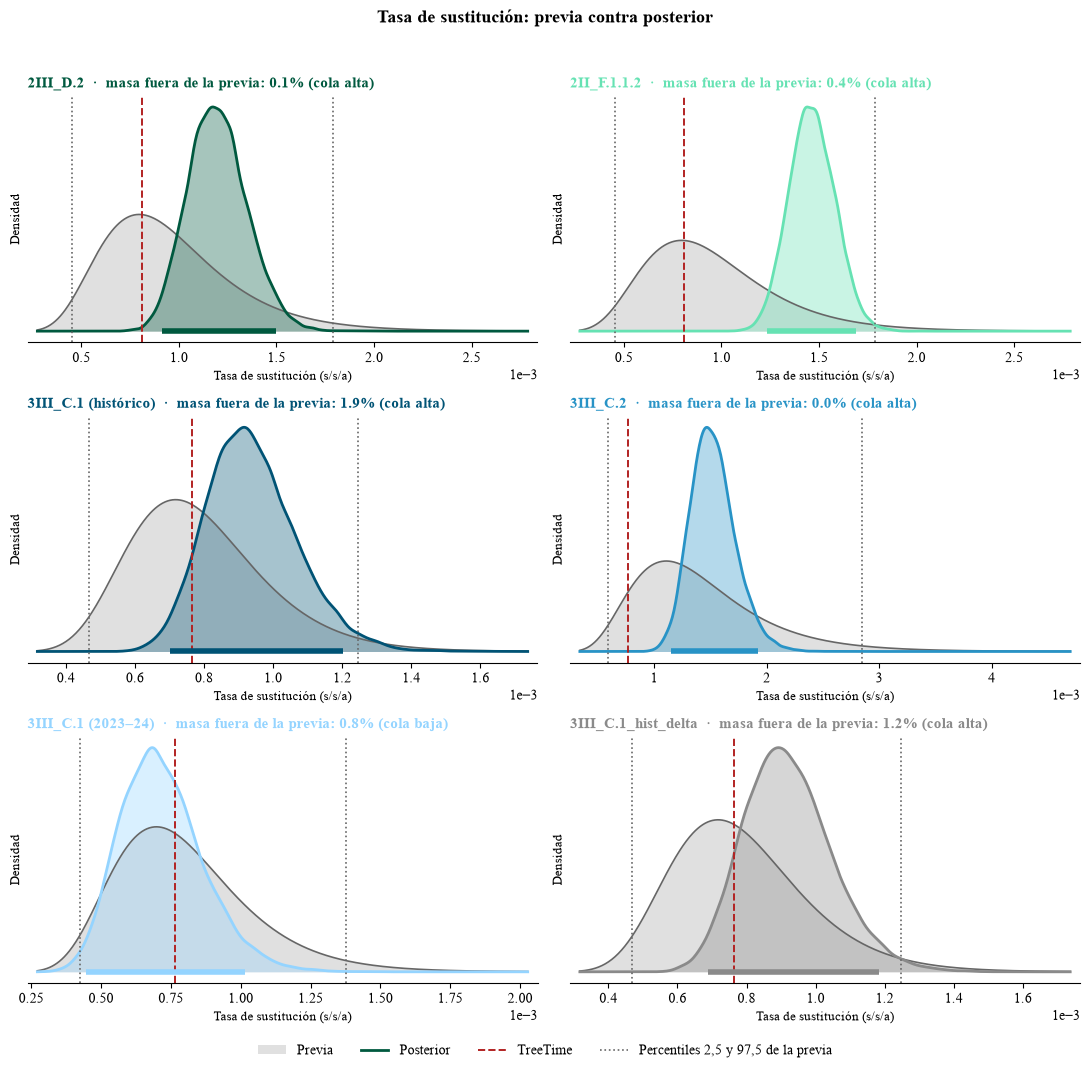


  Guardados: figures/bdsky_reloj_prior_posterior.png · output/bdsky_reloj_prior_posterior.csv


In [60]:
# Contraste de la previa contra el posterior de un parámetro escalar.
#
# PARAMETRO es lo único que hay que cambiar. Con "ucldMean" esta celda es el
# control del reloj del capítulo; con "delta", "origin", "ucldStdev" o
# "gammaShape" hace el mismo control sobre ese otro parámetro, con su tabla, su
# figura y sus archivos. Lo que cambia de un parámetro a otro —título, unidades,
# factor de escala, nombre de archivo, referencia externa contra la que comparar
# y columna acompañante— está junto en PRESENTACION, no repartido por el código.
#
# El criterio operativo del capítulo: si más del 5 % de la masa posterior queda
# más allá de una cola de la previa (percentil 97,5 o 2,5), la previa es
# restricción activa y hay que recentrarla antes de leer nada. Es el control que
# destapó 3III_C.2, cuya previa original dejaba el 67 % de la masa fuera.
#
# Las previas se leen con distribuciones_del_prior() de la celda de diagnóstico:
# un solo lector para todo el notebook, que cubre LogNormal, Exponential, Gamma,
# Beta y Uniform, trae la etiqueta ya formateada y aborta si una LogNormal
# declara meanInRealSpace, porque entonces M no estaría en espacio logarítmico.

from collections import namedtuple

from scipy import stats
from scipy.stats import gaussian_kde

PARAMETRO = "ucldMean"     # ←── la variable que se contrasta
UMBRAL_MASA = 0.05         # 5 % de masa fuera de una cola = restricción activa

PRESENTACION = {
    "ucldMean": dict(
        titulo="Tasa de sustitución", unidades="s/s/a",
        escala=1e4, escala_etiq="10⁻⁴ s/s/a",
        salida="bdsky_reloj_prior_posterior",
        # TreeTime sobre gen E y el dataset completo del serotipo. Es la
        # referencia externa y no es del mismo dato: estos análisis corren sobre
        # un solo linaje, y dos de los seis sobre genoma completo.
        referencia=dict(nombre="TreeTime", por_sero={2: 8.09e-4, 3: 7.64e-4}),
        acompana=dict(col="ucldStdev",
                      nota="Cerca de cero el reloj relajado se comporta como "
                           "estricto y la\n  escala temporal la fija la previa, "
                           "no el dato.")),
    "delta": dict(titulo="Tasa de pérdida de infecciosidad δ", unidades="1/año",
                  salida="bdsky_delta_prior_posterior"),
    "origin": dict(titulo="Origen del proceso",
                   unidades="años antes de la muestra más reciente"),
    "ucldStdev": dict(titulo="Desviación del reloj relajado", unidades=""),
    "gammaShape": dict(titulo="Forma de la Γ de tasas por sitio", unidades=""),
}
POR_OMISION = dict(titulo=None, unidades="", escala=1.0, escala_etiq=None,
                   salida=None, referencia=None, acompana=None)

# La réplica de control del prior de δ sobre el bloque histórico de DENV-3. No
# es una sexta unidad de análisis y no entra en la tabla de convergencia, pero
# en los contrastes contra la previa interesa verla. Va en gris, y no en el tono
# de DENV-3 que le daría la paleta, para que no se lea como una unidad más.
CONTROL = dict(tag="DENV3_3III_C1_hist_delta", sero=3, color="#8A8A8A",
               etiq="3III_C.1_hist_delta", papel="control del prior de δ")

Previa = namedtuple("Previa", "parametro spec pars dist etiqueta")

_ETIQUETA = {
    "LogNormal":   lambda p: f"LogNormal(M = {p['M']:g}; S = {p['S']:g})",
    "Exponential": lambda p: f"Exponential(media = {p['mean']:g})",
    "Gamma":       lambda p: f"Gamma(α = {p['alpha']:g}; escala = {p['beta']:g})",
    "Beta":        lambda p: f"Beta(α = {p['alpha']:g}; β = {p['beta']:g})",
    "Uniform":     lambda p: f"Uniform({p['lower']:g}; {p['upper']:g})",
}


def distribuciones_del_prior(tag):
    """{id del prior: Previa}, leído del XML.

    Es el único lector de previas del notebook. Se lee del XML y no se escribe
    a mano para que los contrastes sigan al generador si se cambia una previa.
    Falla si una LogNormal declara meanInRealSpace, porque entonces M no
    estaría en escala logarítmica.
    """
    x = open(LIN_XML.format(tag), encoding="utf-8").read()
    bloque = re.search(r'<distribution id="prior".*?(?=<distribution id="likelihood")',
                       x, re.S).group(0)
    fuera = {}
    for m in re.finditer(r'<prior id="([^"]+)"[^>]*x="@(\w+)"[^>]*>(.*?)</prior>',
                         bloque, re.S):
        pid, par, cuerpo = m.group(1), m.group(2), m.group(3)
        tipo = re.search(r'<(LogNormal|Exponential|Gamma|Beta|Uniform)\b',
                         cuerpo).group(1)
        p = {k: float(v) for k, v in
             re.findall(r'name="(M|S|mean|alpha|beta|lower|upper)"[^>]*>([^<]+)<',
                        cuerpo)}
        if tipo == "LogNormal":
            if "meanInRealSpace" in cuerpo:
                raise ValueError(f"{tag}/{pid}: meanInRealSpace, M no está en log")
            d = stats.lognorm(s=p["S"], scale=np.exp(p["M"]))
        elif tipo == "Exponential":
            d = stats.expon(scale=p["mean"])
        elif tipo == "Gamma":
            d = stats.gamma(p["alpha"], scale=p["beta"])   # beta = escala en BEAST2
        elif tipo == "Beta":
            d = stats.beta(p["alpha"], p["beta"])
        else:
            d = stats.uniform(loc=p["lower"], scale=p["upper"] - p["lower"])
        fuera[pid] = Previa(par, tipo, p, d, _ETIQUETA[tipo](p))
    return fuera


def columnas_de(par, cols):
    """origin -> ['origin'] · Re -> ['Re.1' ... 'Re.n'], en orden."""
    if par in cols:
        return [par]
    hijas = [c for c in cols if re.fullmatch(re.escape(par) + r"\.\d+", c)]
    if not hijas:
        raise KeyError(f"{par}: no hay columna en el log")
    return sorted(hijas, key=lambda c: int(c.split(".")[-1]))


UNIDADES = LINAJES + [CONTROL]
COLOR_DE = {a["etiq"]: a["color"] for a in UNIDADES}
SERO_DE = {a["etiq"]: a["sero"] for a in UNIDADES}


def presentacion_de(par):
    """Los ajustes de ese parámetro, con los valores por omisión rellenados."""
    cfg = dict(POR_OMISION, **PRESENTACION.get(par, {}))
    cfg["titulo"] = cfg["titulo"] or par
    cfg["salida"] = cfg["salida"] or f"bdsky_{par}_prior_posterior"
    cfg["escala_etiq"] = cfg["escala_etiq"] or cfg["unidades"] or "unidades del XML"
    return cfg


def prior_de(tag, par):
    """La Previa que el XML declara para ese parámetro."""
    for pv in distribuciones_del_prior(tag).values():
        if pv.parametro == par:
            return pv
    raise KeyError(f"{tag}: el XML no declara previa para {par}")


def masa_fuera(x, dist):
    """Fracción de la masa posterior más allá de cada cola de la previa."""
    return (float((x > dist.ppf(0.975)).mean()),
            float((x < dist.ppf(0.025)).mean()))


def contraste_prior(par, unidades=None):
    """(tabla, {etiqueta: (traza, previa)}) del contraste de ese parámetro."""
    cfg = presentacion_de(par)
    unidades = unidades or UNIDADES

    # Un vector como Re no cabe en esta celda: tiene un valor por intervalo y
    # su contraste es el de la celda siguiente. Se avisa aqui y no con el error
    # de usecols de pandas, que no dice por que.
    cabecera = pd.read_csv(LIN_LOG.format(unidades[0]["tag"]), sep="	",
                           comment="#", nrows=0).columns
    if par not in cabecera:
        raise ValueError(
            f"{par} no es una columna escalar del .log: es un vector "
            f"({', '.join(columnas_de(par, cabecera))}). Esta celda contrasta "
            f"parametros escalares; para Re esta la celda siguiente.")

    filas, trazas = [], {}
    for a in unidades:
        cols = [par] + ([cfg["acompana"]["col"]] if cfg["acompana"] else [])
        log = pd.read_csv(LIN_LOG.format(a["tag"]), sep="\t", comment="#",
                          usecols=cols)
        if BURNIN:
            log = log.iloc[int(len(log) * BURNIN):]
        x = log[par].to_numpy()
        pv = prior_de(a["tag"], par)
        trazas[a["etiq"]] = (x, pv.dist)

        lo, hi = hpd(x)
        arriba, abajo = masa_fuera(x, pv.dist)
        med = float(np.median(x))
        fila = dict(unidad=a["etiq"], parametro=par, prior=pv.etiqueta,
                    prior_mediana=pv.dist.median(),
                    prior_lo=pv.dist.ppf(0.025), prior_hi=pv.dist.ppf(0.975),
                    post_mediana=med, post_lo=lo, post_hi=hi,
                    razon_prior=med / pv.dist.median(),
                    masa_arriba=arriba, masa_abajo=abajo,
                    activa=bool(max(arriba, abajo) > UMBRAL_MASA))
        if cfg["referencia"]:
            v = cfg["referencia"]["por_sero"][a["sero"]]
            fila.update(ref_nombre=cfg["referencia"]["nombre"], ref_valor=v,
                        razon_ref=med / v, ref_en_hpd=bool(lo <= v <= hi))
        if cfg["acompana"]:
            c = cfg["acompana"]["col"]
            fila[c] = float(np.median(log[c].to_numpy()))
        filas.append(fila)
    return pd.DataFrame(filas), trazas


def _rango(lo, hi, d=2):
    return "[" + lo.round(d).astype(str) + "; " + hi.round(d).astype(str) + "]"


def _pct(s, d=2):
    return (s * 100).round(d).astype(str) + " %"


def imprime_contraste(par, tabla):
    cfg = presentacion_de(par)
    f = cfg["escala"]
    e = tabla.copy()
    for c in ("prior_mediana", "post_mediana", "ref_valor"):
        if c in e:
            e[c] = e[c] * f
    e["prior 95 %"] = _rango(tabla.prior_lo * f, tabla.prior_hi * f)
    e["post HPD 95 %"] = _rango(tabla.post_lo * f, tabla.post_hi * f)
    e["masa >p97,5"] = _pct(tabla.masa_arriba)
    e["masa <p2,5"] = _pct(tabla.masa_abajo)

    cols = ["unidad", "prior", "prior_mediana", "prior 95 %", "post_mediana",
            "post HPD 95 %", "razon_prior", "masa >p97,5", "masa <p2,5"]
    nom = {"prior_mediana": "previa med.", "post_mediana": "post med.",
           "razon_prior": "post/previa"}
    if cfg["referencia"]:
        r = cfg["referencia"]["nombre"]
        cols += ["ref_valor", "razon_ref", "ref_en_hpd"]
        nom.update(ref_valor=r, razon_ref=f"post/{r}", ref_en_hpd=f"{r} en HPD")

    print(f"{cfg['titulo']} ({par}), en {cfg['escala_etiq']}. "
          f"Mediana posterior y HPD 95 %.\n")
    print(e[cols].rename(columns=nom).round(2).to_string(index=False))

    act = tabla[tabla.activa]["unidad"].tolist()
    print(f"\nRestricción activa de la previa (más del {UMBRAL_MASA:.0%} de masa "
          f"fuera de una cola): " + (", ".join(act) if act else "ninguna"))
    if cfg["acompana"]:
        c = cfg["acompana"]["col"]
        print(f"`{c}` mediana: " + " · ".join(
            f"{r.unidad} {r[c]:.3f}" for _, r in tabla.iterrows())
            + "\n  " + cfg["acompana"]["nota"])


def figura_contraste(par, trazas, guardar=True):
    """Una densidad por unidad: previa en gris, posterior en su color."""
    cfg = presentacion_de(par)
    ref = cfg["referencia"]
    n = len(trazas)
    with plt.rc_context({"font.family": "Times New Roman"}):
        fig, axes = plt.subplots(int(np.ceil(n / 2)), 2,
                                 figsize=(11, 3.5 * int(np.ceil(n / 2))),
                                 squeeze=False)
        for ax, (etiq, (x, pr)) in zip(axes.ravel(), trazas.items()):
            color = COLOR_DE.get(etiq, "#444444")
            rejilla = np.linspace(min(x.min(), pr.ppf(0.001)) * 0.9,
                                  max(x.max(), pr.ppf(0.999)) * 1.05, 600)
            ax.fill_between(rejilla, pr.pdf(rejilla), color="#999999", alpha=0.30,
                            lw=0, label="Previa")
            ax.plot(rejilla, pr.pdf(rejilla), color="#666666", lw=1.2)
            dens = gaussian_kde(x)(rejilla)
            ax.fill_between(rejilla, dens, color=color, alpha=0.35, lw=0)
            ax.plot(rejilla, dens, color=color, lw=2, label="Posterior")

            for q in (0.025, 0.975):
                ax.axvline(pr.ppf(q), color="#666666", ls=":", lw=1.2)
            if ref:
                ax.axvline(ref["por_sero"][SERO_DE[etiq]], color="#B22222",
                           ls="--", lw=1.4, label=ref["nombre"])
            lo, hi = hpd(x)
            ax.plot([lo, hi], [0, 0], color=color, lw=4, solid_capstyle="butt",
                    zorder=5)

            arr, aba = masa_fuera(x, pr)
            cola = "alta" if arr >= aba else "baja"
            ax.set_title(f"{etiq}  ·  masa fuera de la previa: "
                         f"{max(arr, aba):.1%} (cola {cola})",
                         loc="left", fontsize=10.5, fontweight="bold", color=color)
            ax.set_xlabel(f"{cfg['titulo']}"
                          + (f" ({cfg['unidades']})" if cfg["unidades"] else ""),
                          fontsize=9.5)
            ax.set_ylabel("Densidad", fontsize=9.5)
            ax.set_yticks([])
            ax.spines[["top", "right", "left"]].set_visible(False)
            ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
            ax.margins(x=0.02)
        for ax in axes.ravel()[n:]:
            ax.set_visible(False)

        h, l = axes.ravel()[0].get_legend_handles_labels()
        h.append(Line2D([], [], color="#666666", ls=":", lw=1.2))
        l.append("Percentiles 2,5 y 97,5 de la previa")
        fig.legend(h, l, loc="lower center", ncol=4, frameon=False, fontsize=10,
                   bbox_to_anchor=(0.5, -0.015))
        fig.suptitle(f"{cfg['titulo']}: previa contra posterior",
                     fontsize=13, fontweight="bold", y=0.995)
        fig.tight_layout(rect=[0, 0.015, 1, 0.975])
        if guardar:
            fig.savefig(f"../figures/{cfg['salida']}.png", dpi=300,
                        bbox_inches="tight")
        plt.show()
        plt.close(fig)


# ──────────────────────────── el contraste ────────────────────────────
_cfg = presentacion_de(PARAMETRO)

tabla_contraste, trazas_contraste = contraste_prior(PARAMETRO)
tabla_contraste.to_csv(f"../output/{_cfg['salida']}.csv", index=False)
imprime_contraste(PARAMETRO, tabla_contraste)
figura_contraste(PARAMETRO, trazas_contraste)
print(f"\n  Guardados: figures/{_cfg['salida']}.png · "
      f"output/{_cfg['salida']}.csv")


Prior de Re: LogNormal(0; 0.5) en los seis análisis · mediana 1.00 · HPD 95 % [0.26; 2.32], ancho 2.06

              unidad  intervalo  tallo  mediana     HPD 95 %  ancho reduc. masa fuera  activa  informativo
            2III_D.2          1  False    1.040 [1.01; 1.09]  0.080 96.1 %      0.0 %   False         True
            2III_D.2          2  False    1.076  [0.86; 1.3]  0.439 78.7 %      0.0 %   False        False
            2III_D.2          3  False    0.708 [0.44; 0.93]  0.492 76.1 %     1.09 %   False         True
            2III_D.2          4  False    0.835 [0.56; 1.07]  0.517 74.9 %     0.17 %   False        False
            2III_D.2          5  False    1.209 [0.96; 1.49]  0.529 74.3 %      0.0 %   False        False
            2III_D.2          6  False    1.455  [1.2; 1.77]  0.572 72.2 %      0.0 %   False         True
            2III_D.2          7   True    0.799 [0.59; 0.96]  0.368 82.1 %     0.02 %   False         True
         2II_F.1.1.2          1  False  

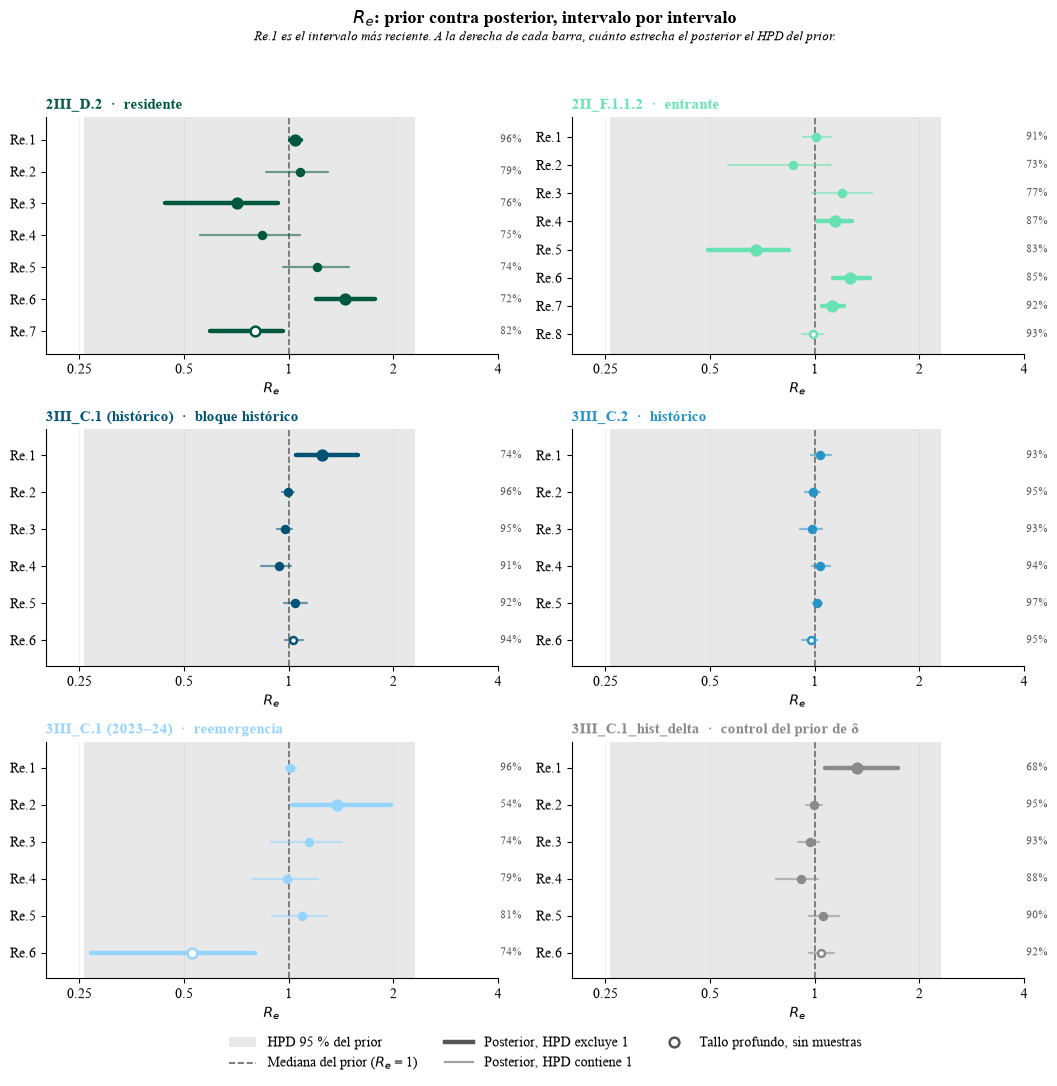


  Guardados: figures/bdsky_Re_prior_posterior.png · output/bdsky_Re_prior_posterior.csv


In [41]:
# Prior contra posterior de Re, intervalo por intervalo.
#
# Tres medidas por intervalo, y las tres dicen cosas distintas:
#
#   · masa fuera de las colas del prior: si pasa del 5 %, el prior es
#     restricción activa y el intervalo no se puede leer como estimación;
#   · reducción del ancho del HPD respecto al del prior: cuánta incertidumbre
#     quitó el dato. Cerca de cero el posterior es el prior;
#   · si el HPD excluye 1: si el intervalo dice algo sobre crecimiento.
#
# Un detalle que conviene tener presente al leer los skylines: el prior de Re es
# LogNormal(0; 0,5) en los seis análisis, y su mediana es exp(0) = 1 exacto. Un
# intervalo sin información devuelve 1 por construcción. Lo que distingue «sin
# información» de «informado hacia 1» es el ancho: el prior tiene un HPD 95 %
# de unas 2,2 unidades, así que un intervalo que devuelve 1 con un HPD de 0,1
# está informado, no vacío.
#
# ADVERTENCIA de alcance: esto compara el posterior con el prior PARAMÉTRICO
# marginal de Re, que no es el prior efectivo. BDSKY acopla Re con origin, δ,
# sProp y el árbol, de modo que el prior inducido sobre Re no es esta LogNormal.
# La comprobación que cerraría el asunto es una corrida con sampleFromPrior, que
# sigue pendiente en la bitácora. Mientras no esté, este control detecta priors
# que son restricción activa, y no demuestra que un intervalo informativo lo sea
# por el dato y no por la estructura del modelo.

N_PRIOR = 200_000         # muestras del prior, para medir su HPD con hpd()

filas = []
for a in UNIDADES:
    log = pd.read_csv(LIN_LOG.format(a["tag"]), sep="\t", comment="#")
    cols = sorted([c for c in log.columns if re.fullmatch(r"Re\.\d+", c)],
                  key=lambda c: int(c.split(".")[-1]))
    pv = prior_de(a["tag"], "Re")
    pr = pv.dist
    # el HPD del prior se mide con la misma función que el del posterior, para
    # que los dos anchos sean comparables sin corregir por asimetría
    p_lo, p_hi = hpd(pr.rvs(N_PRIOR, random_state=0))

    for i, c in enumerate(cols):
        x = log[c].to_numpy()
        lo, hi = hpd(x)
        arriba, abajo = masa_fuera(x, pr)
        filas.append(dict(
            unidad=a["etiq"], intervalo=i + 1, tallo=(i + 1 == len(cols)),
            prior=pv.etiqueta,
            prior_mediana=pr.median(), prior_lo=p_lo, prior_hi=p_hi,
            mediana=float(np.median(x)), lo=lo, hi=hi,
            ancho=hi - lo, ancho_prior=p_hi - p_lo,
            reduccion=1 - (hi - lo) / (p_hi - p_lo),
            masa_arriba=arriba, masa_abajo=abajo,
            activa=bool(max(arriba, abajo) > UMBRAL_MASA),
            informativo=bool(lo > 1 or hi < 1)))

tabla_re_pp = pd.DataFrame(filas)
tabla_re_pp.to_csv("../output/bdsky_Re_prior_posterior.csv", index=False)

print(f"Prior de Re: {tabla_re_pp.prior.iloc[0]} en los seis análisis · "
      f"mediana {tabla_re_pp.prior_mediana.iloc[0]:.2f} · "
      f"HPD 95 % [{tabla_re_pp.prior_lo.iloc[0]:.2f}; "
      f"{tabla_re_pp.prior_hi.iloc[0]:.2f}], ancho "
      f"{tabla_re_pp.ancho_prior.iloc[0]:.2f}\n")
_v = tabla_re_pp.copy()
_v["HPD 95 %"] = ("[" + _v.lo.round(2).astype(str) + "; "
                  + _v.hi.round(2).astype(str) + "]")
_v["reduc."] = (_v.reduccion * 100).round(1).astype(str) + " %"
_v["masa fuera"] = ((_v.masa_arriba + _v.masa_abajo) * 100).round(2).astype(str) + " %"
print(_v[["unidad", "intervalo", "tallo", "mediana", "HPD 95 %", "ancho",
          "reduc.", "masa fuera", "activa", "informativo"]]
      .round(3).to_string(index=False))

_act = tabla_re_pp[tabla_re_pp.activa]
print(f"\nIntervalos con más del {UMBRAL_MASA:.0%} de masa fuera de una cola del "
      f"prior: {len(_act)} de {len(tabla_re_pp)}"
      + ("" if _act.empty else "\n" + _act.groupby("unidad").intervalo
         .apply(lambda s: ", ".join(map(str, s))).to_string()))
print("\nReducción del ancho del HPD respecto al prior, por unidad "
      "(mín–máx sobre sus intervalos):")
for u, g in tabla_re_pp.groupby("unidad", sort=False):
    s = g[~g.tallo]
    print(f"  {u:22s} {s.reduccion.min():6.1%} – {s.reduccion.max():6.1%}"
          f"   tallo profundo {g[g.tallo].reduccion.iloc[0]:6.1%}")

# ───────────────────────────── la figura ─────────────────────────────
with plt.rc_context({"font.family": "Times New Roman"}):
    fig, axes = plt.subplots(3, 2, figsize=(11, 10.5))
    for ax, a in zip(axes.ravel(), UNIDADES):
        t = tabla_re_pp[tabla_re_pp.unidad == a["etiq"]]
        y = np.arange(len(t))[::-1]          # Re.1 arriba, el más reciente

        ax.axvspan(t.prior_lo.iloc[0], t.prior_hi.iloc[0], color="#999999",
                   alpha=0.22, lw=0, zorder=0)
        ax.axvline(t.prior_mediana.iloc[0], color="#666666", ls="--", lw=1.2,
                   zorder=1)
        for yy, (_, r) in zip(y, t.iterrows()):
            ax.plot([r.lo, r.hi], [yy, yy], color=a["color"],
                    lw=3.2 if r.informativo else 1.6,
                    alpha=1.0 if r.informativo else 0.55, solid_capstyle="round",
                    zorder=3)
            ax.plot(r.mediana, yy, "o", ms=7 if r.informativo else 5,
                    mfc="white" if r.tallo else a["color"],
                    mec=a["color"], mew=1.8, zorder=4)
            ax.annotate(f"{r.reduccion:.0%}", (1.005, yy), xycoords=("axes fraction",
                        "data"), va="center", fontsize=8, color="#555555",
                        annotation_clip=False)

        ax.set_yticks(y)
        ax.set_yticklabels([f"Re.{i}" for i in t.intervalo])
        ax.set_ylim(-0.7, len(t) - 0.3)
        ax.set_xscale("log")
        ax.set_xlim(0.2, 4.0)
        ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(
            lambda v, _: f"{v:g}"))
        ax.xaxis.set_major_locator(matplotlib.ticker.FixedLocator(
            [0.25, 0.5, 1, 2, 4]))
        ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
        ax.set_xlabel("$R_e$", fontsize=10)
        ax.set_title(f"{a['etiq']}  ·  {a['papel']}", loc="left", fontsize=10.5,
                     fontweight="bold", color=a["color"])
        ax.grid(axis="x", alpha=0.18, lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)

    h = [Patch(facecolor="#999999", alpha=0.22, label="HPD 95 % del prior"),
         Line2D([], [], color="#666666", ls="--", lw=1.2,
                label="Mediana del prior ($R_e$ = 1)"),
         Line2D([], [], color="#555555", lw=3.2, label="Posterior, HPD excluye 1"),
         Line2D([], [], color="#555555", lw=1.6, alpha=0.55,
                label="Posterior, HPD contiene 1"),
         Line2D([], [], marker="o", ls="", mfc="white", mec="#555555", mew=1.8,
                ms=7, label="Tallo profundo, sin muestras")]
    fig.legend(handles=h, loc="lower center", ncol=3, frameon=False, fontsize=10,
               bbox_to_anchor=(0.5, -0.025))
    fig.suptitle("$R_e$: prior contra posterior, intervalo por intervalo",
                 fontsize=13, fontweight="bold", y=0.997)
    fig.text(0.5, 0.968, "Re.1 es el intervalo más reciente. A la derecha de cada "
             "barra, cuánto estrecha el posterior el HPD del prior.",
             ha="center", fontsize=9.5, style="italic")
    fig.tight_layout(rect=[0, 0.02, 0.97, 0.958])
    fig.savefig("../figures/bdsky_Re_prior_posterior.png", dpi=300,
                bbox_inches="tight")
    plt.show()
    plt.close(fig)
print("\n  Guardados: figures/bdsky_Re_prior_posterior.png · "
      "output/bdsky_Re_prior_posterior.csv")


### ML Tree vs Original Map

DENV1: 683 hojas | 105 con coordenadas
   árbol podado a 105 hojas
   con grupo asignado: 105 de 105 | 4 categorías


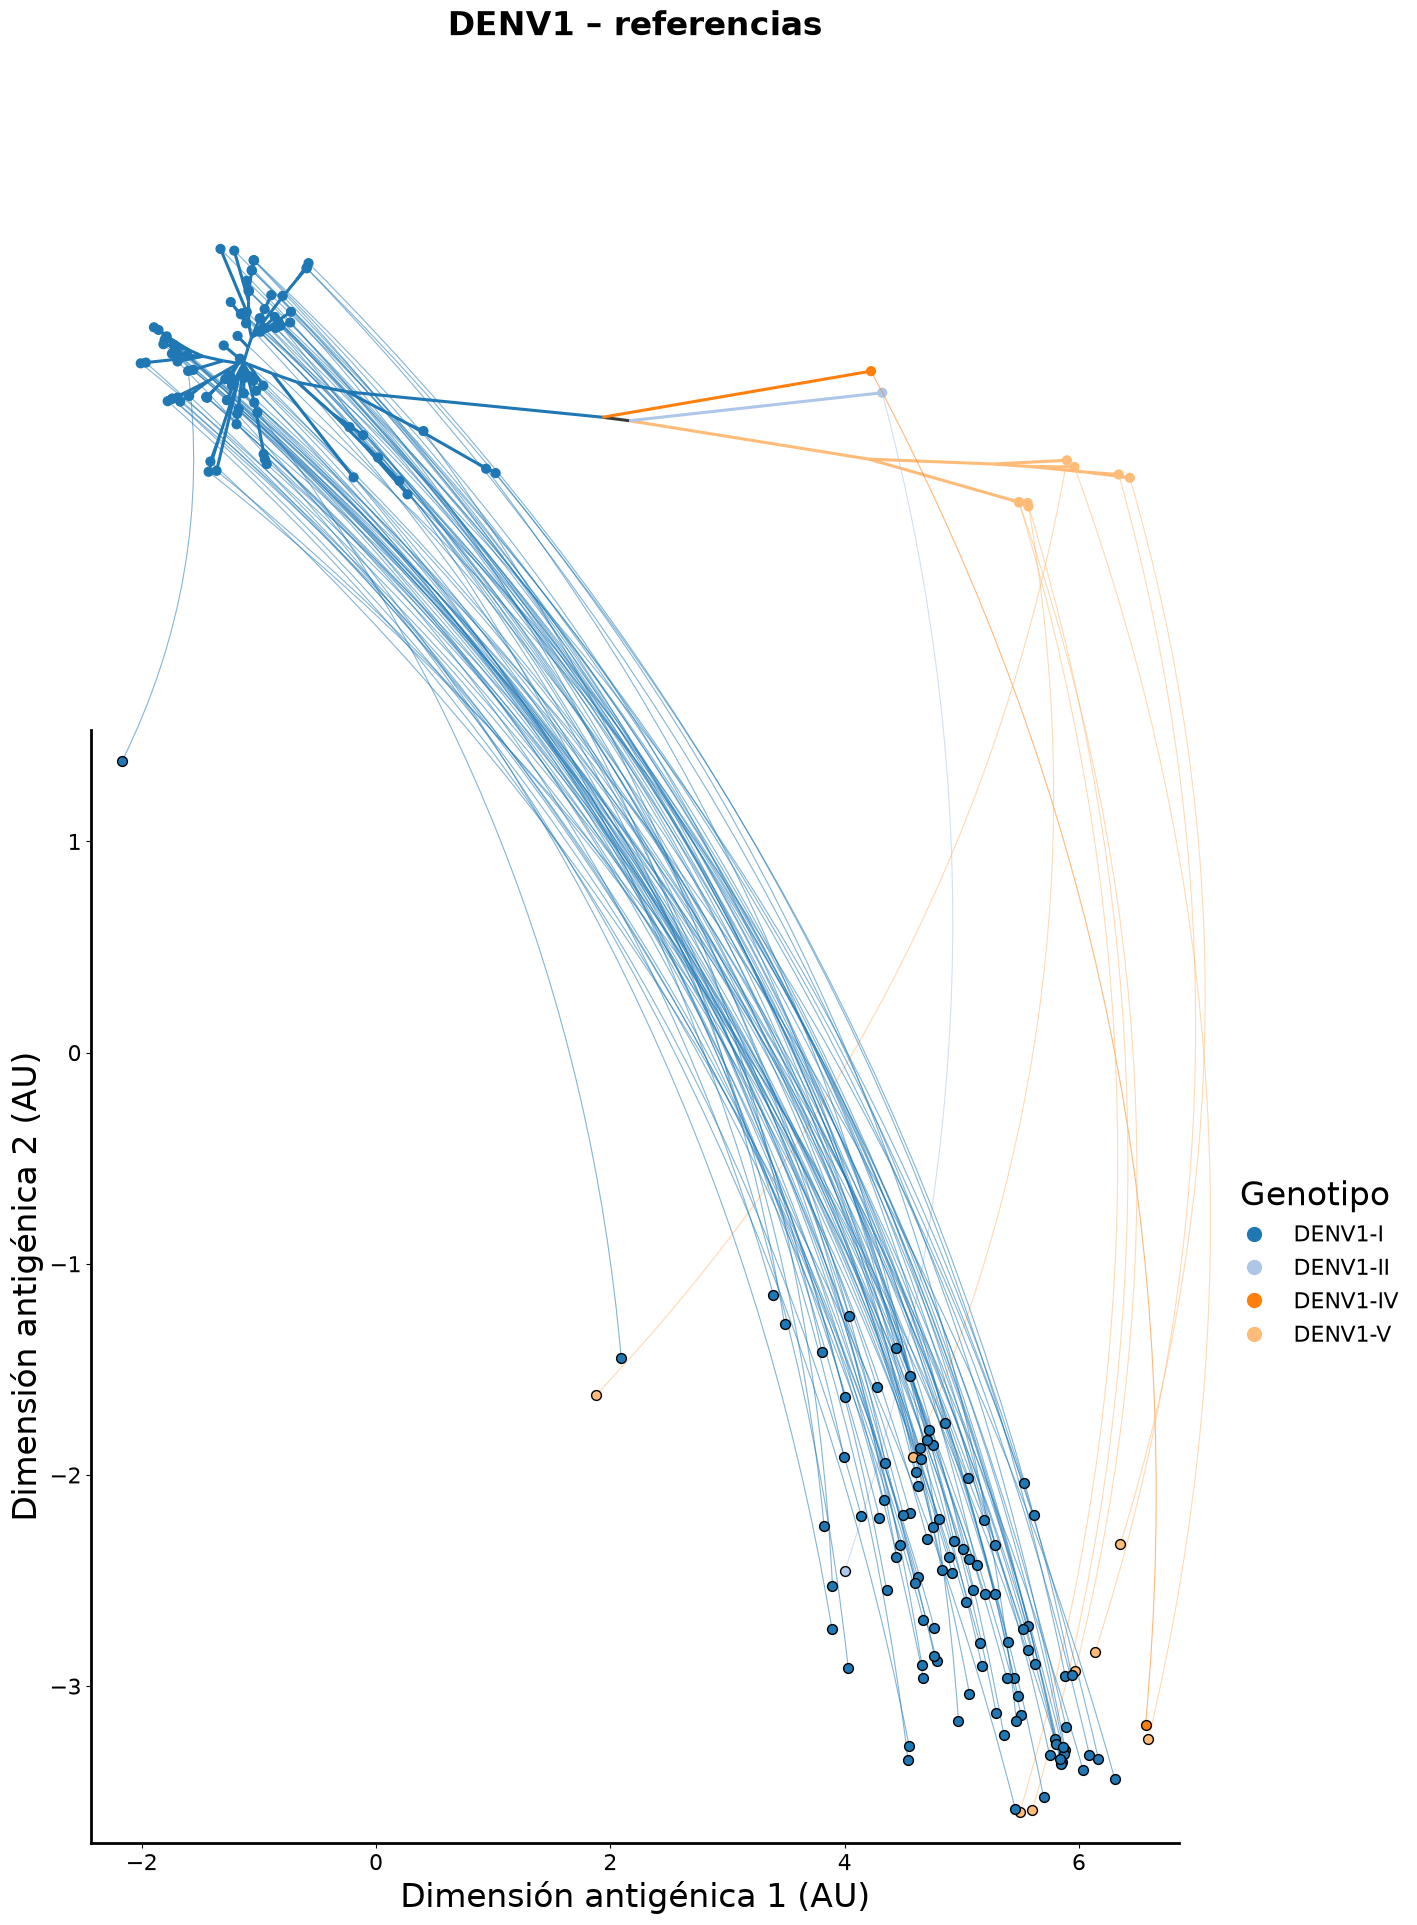

DENV2: 456 hojas | 96 con coordenadas
   árbol podado a 96 hojas
   con grupo asignado: 96 de 96 | 6 categorías


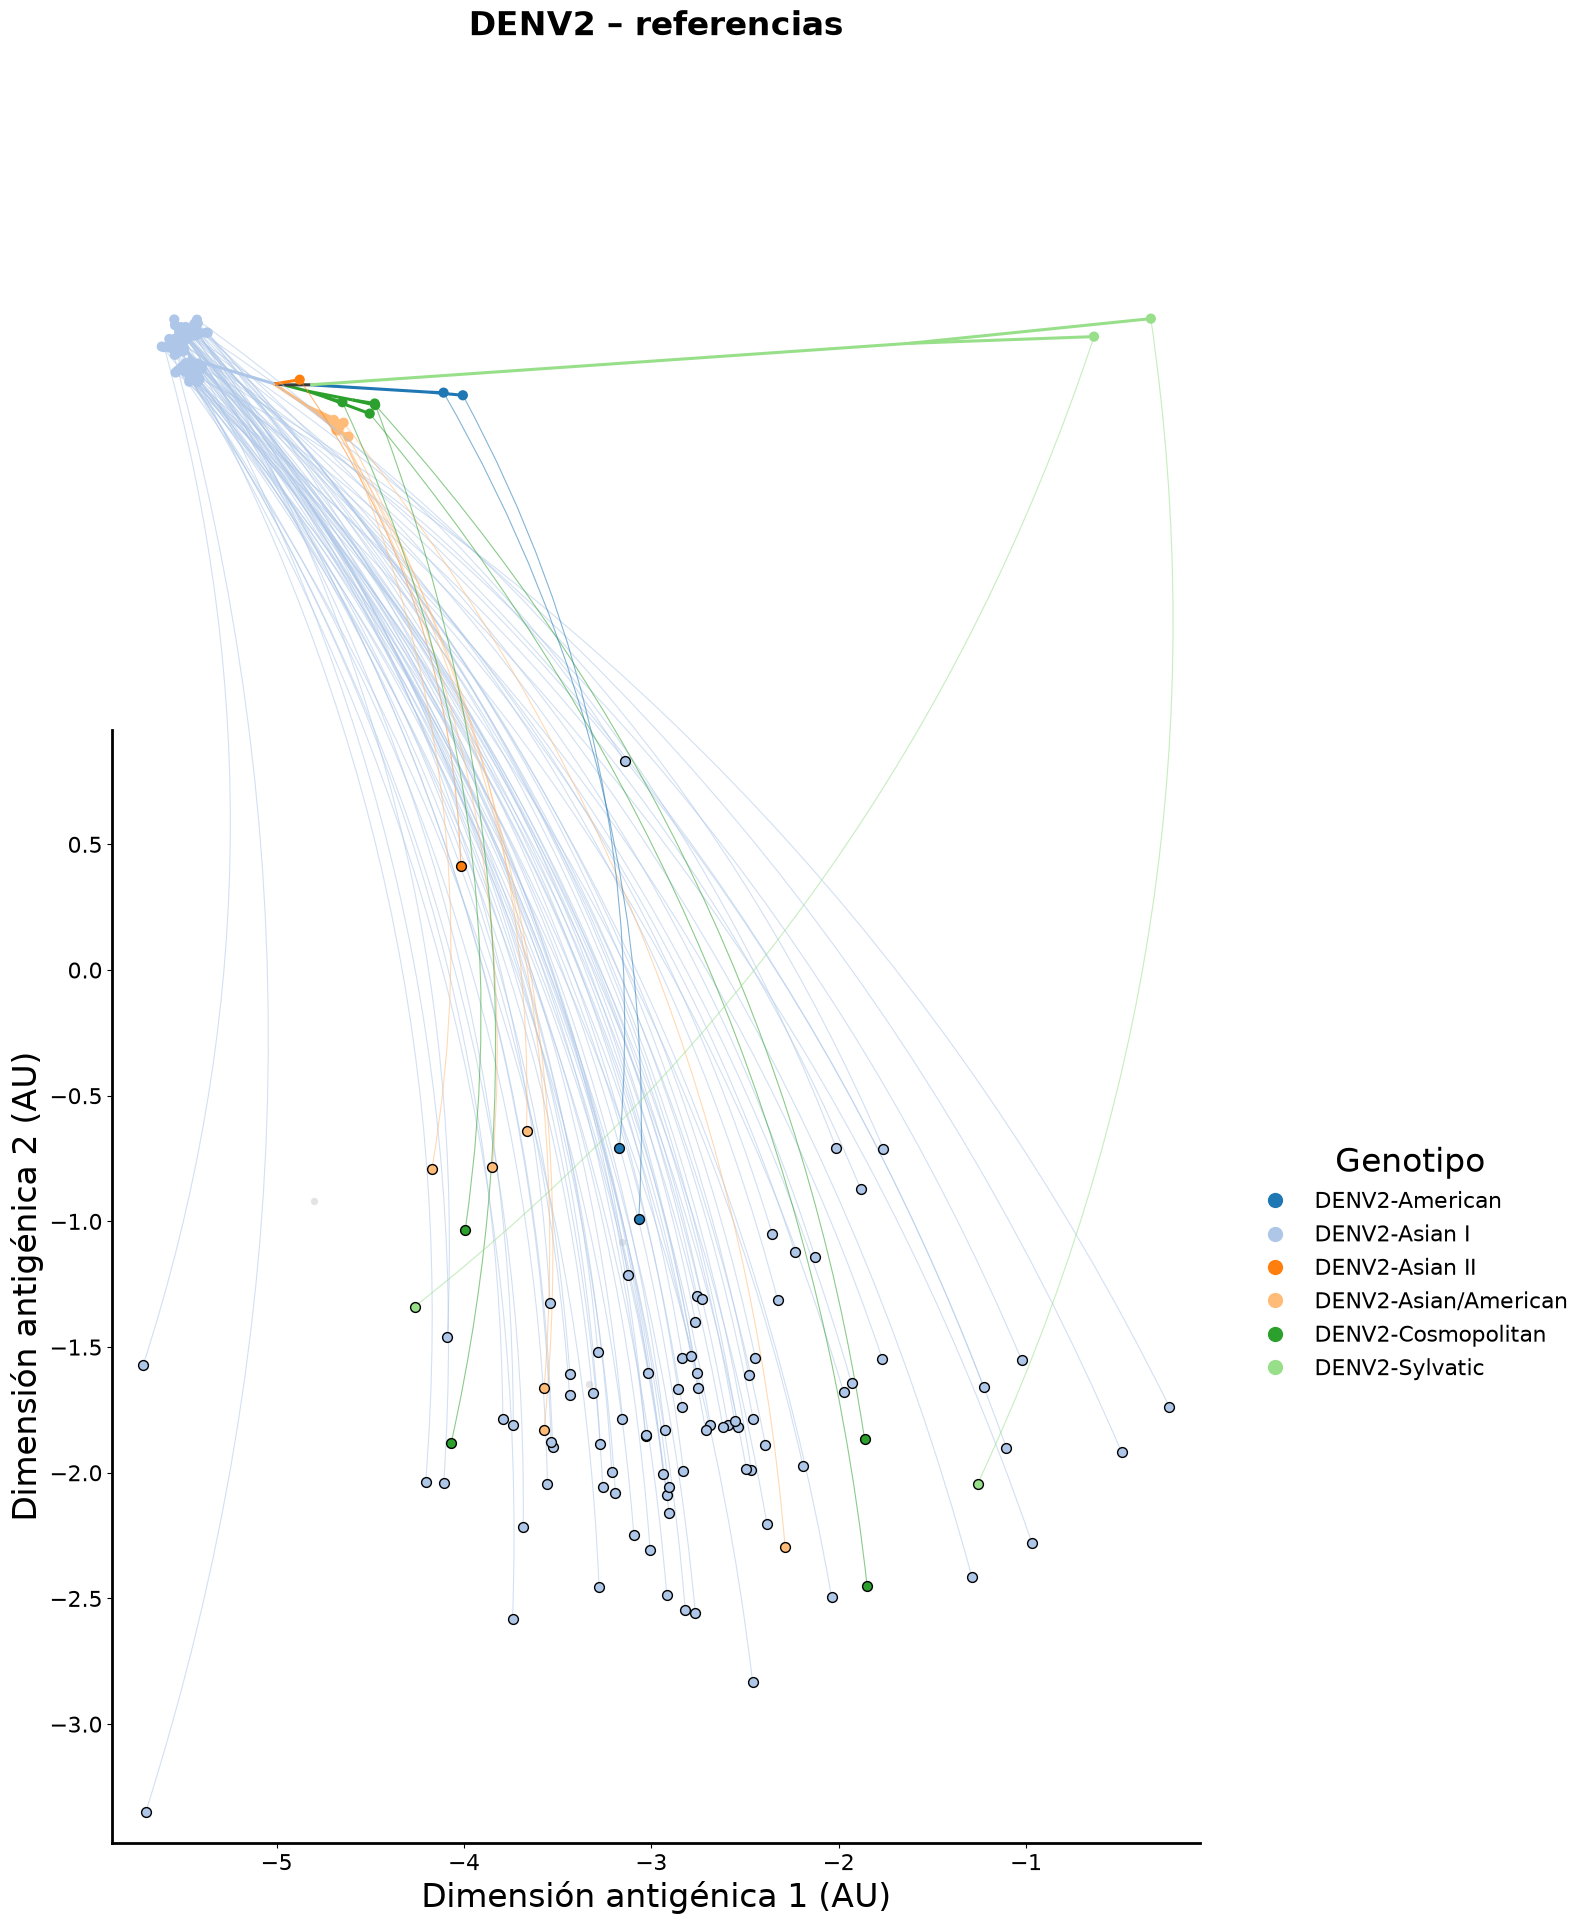

DENV3: 472 hojas | 102 con coordenadas
   árbol podado a 102 hojas
   con grupo asignado: 102 de 102 | 4 categorías


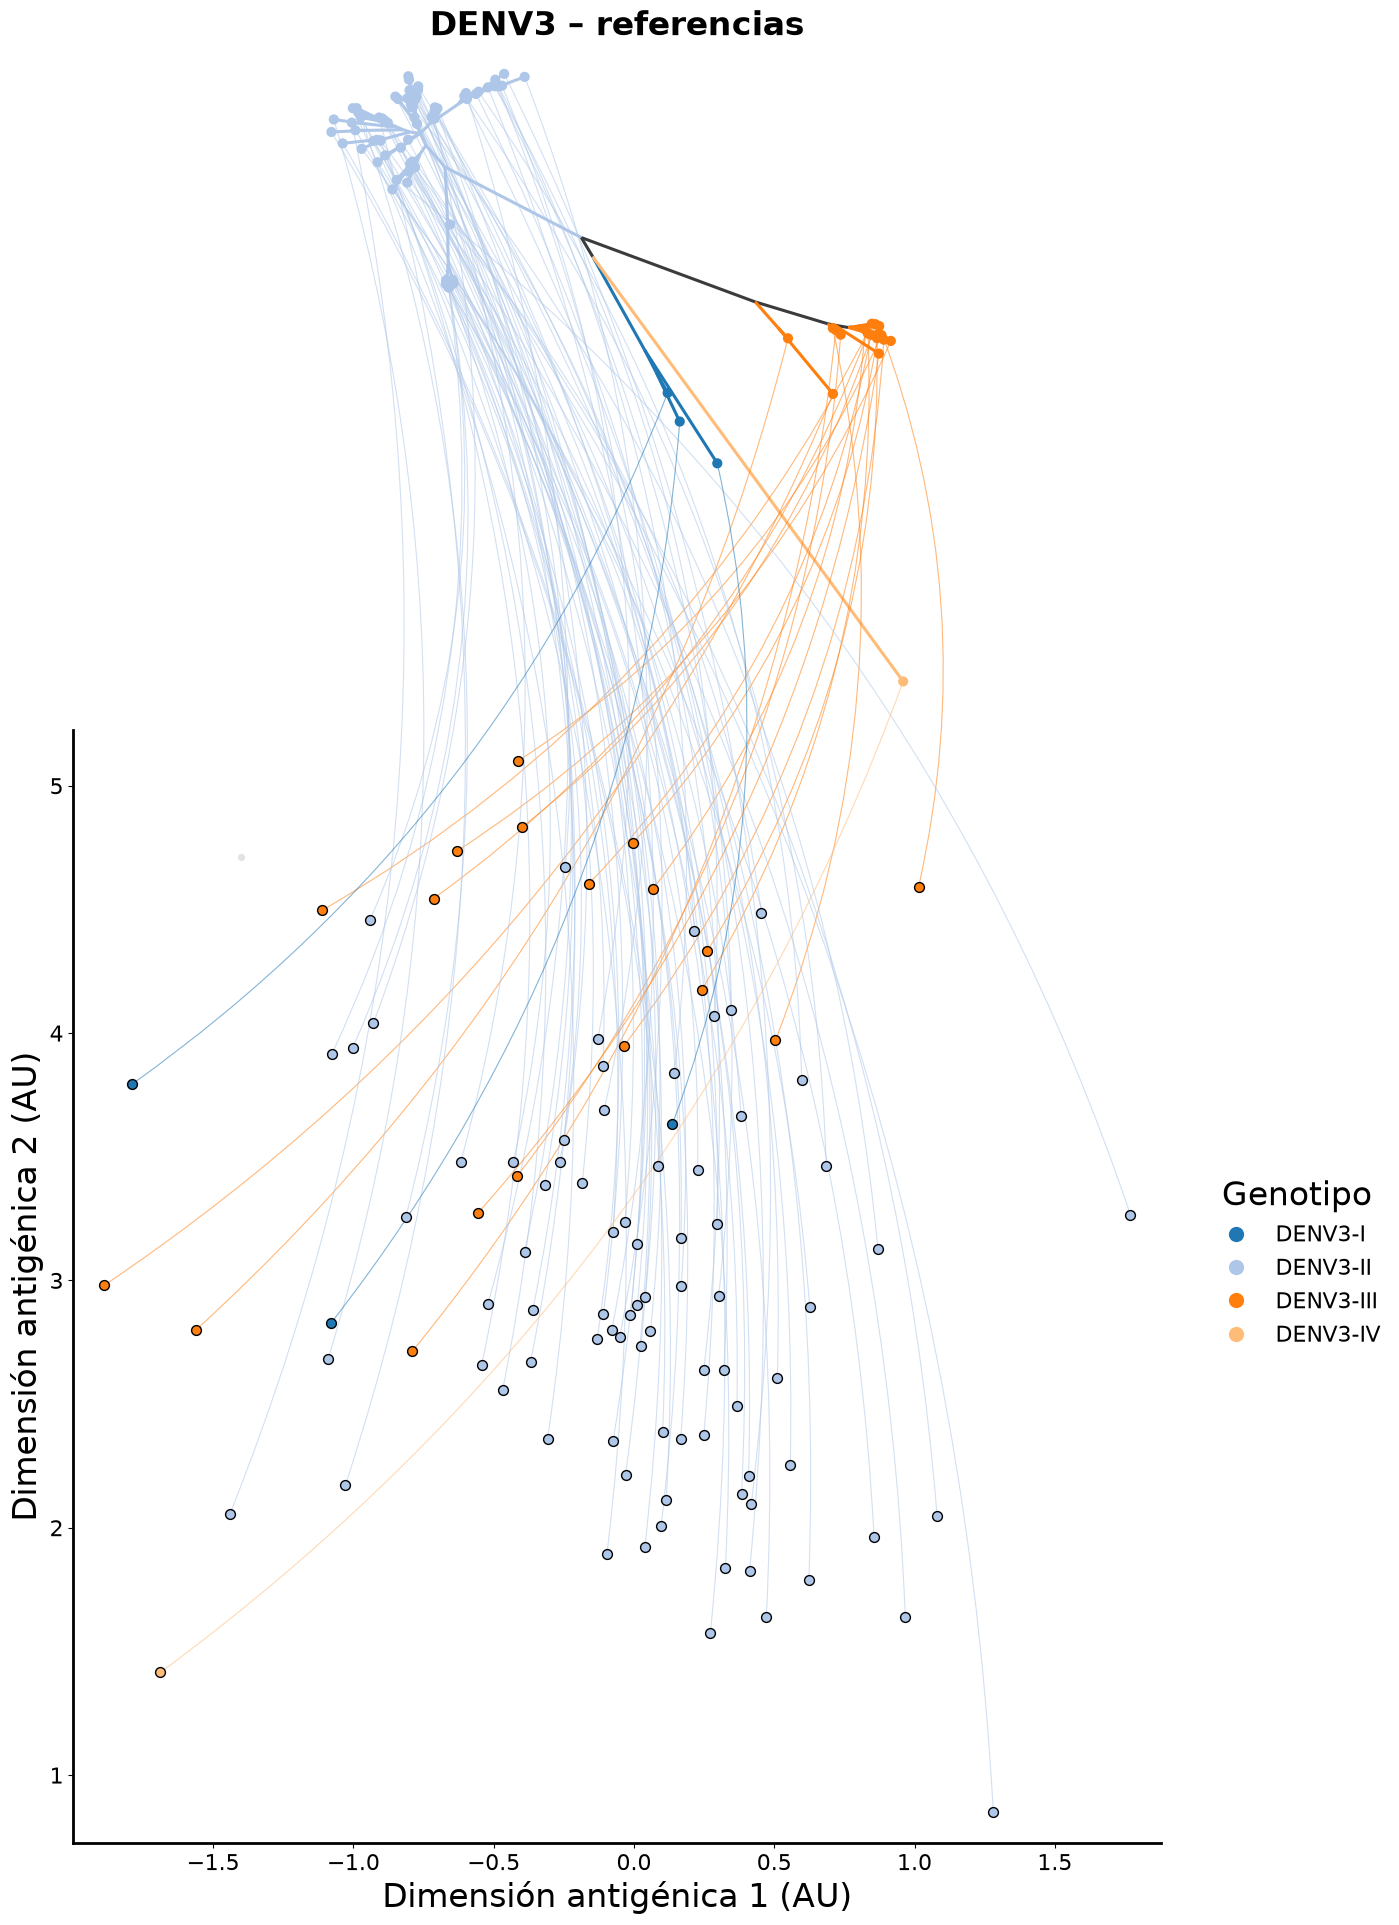

DENV4: 394 hojas | 101 con coordenadas
   árbol podado a 101 hojas
   con grupo asignado: 101 de 101 | 4 categorías


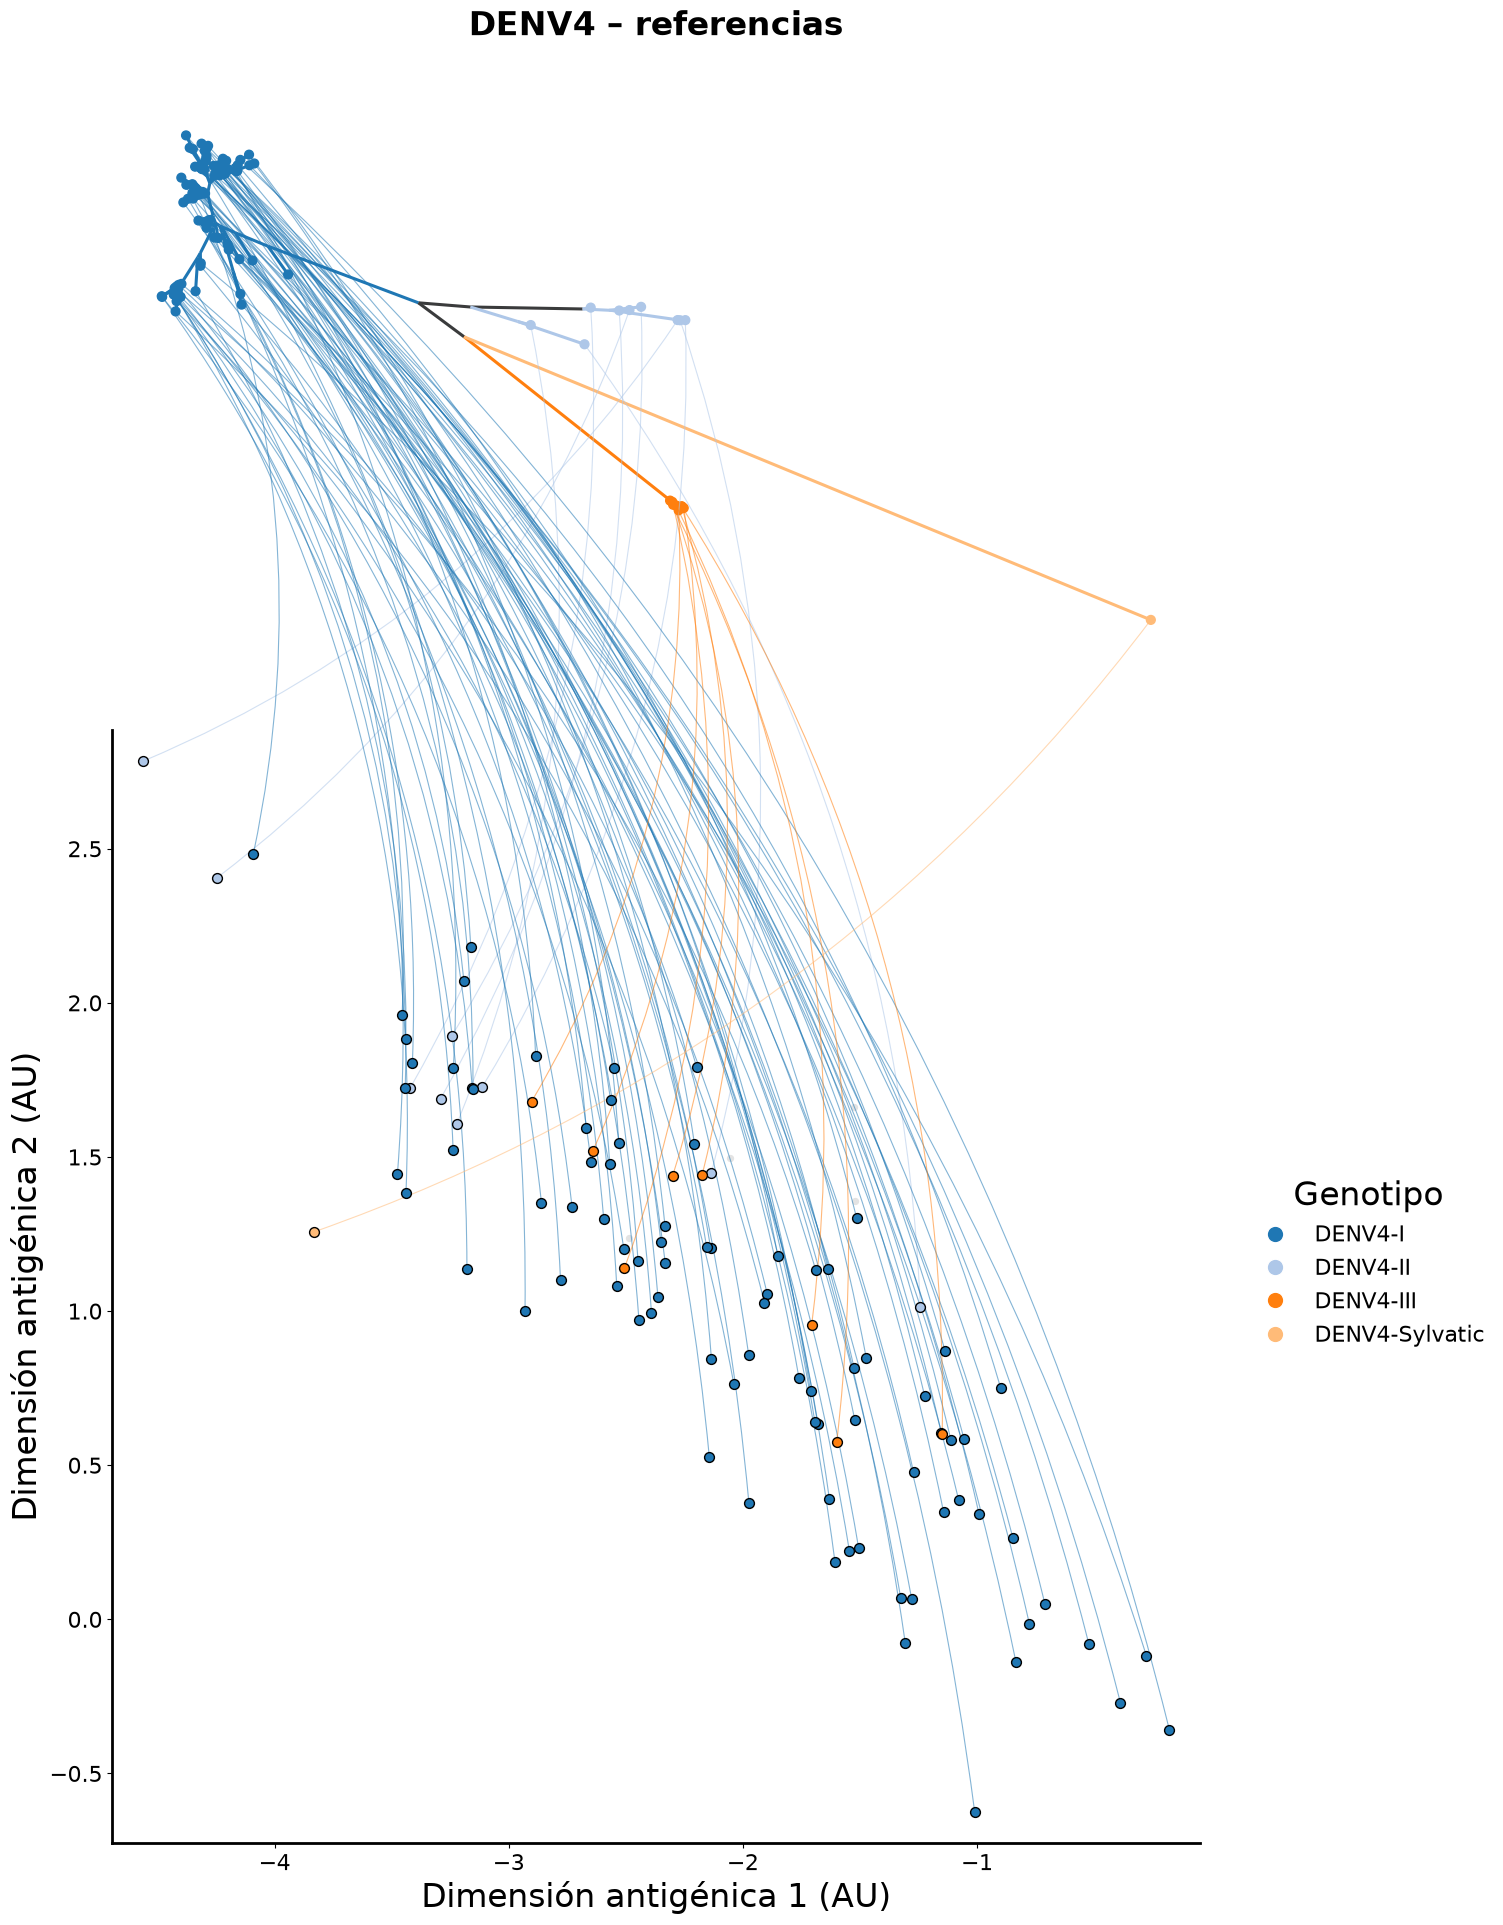

In [42]:
import io, re, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
from matplotlib.collections import LineCollection
from matplotlib.patches import ConnectionPatch
from matplotlib.lines import Line2D
from Bio import Phylo

sys.setrecursionlimit(10000)
GREY = "#999999"


# ───────────── 1) Leer el árbol MCC de BEAST (.tree, Nexus) ─────────────
def load_mcc(path):
    """Lee un árbol en Nexus (MCC de BEAST) o en Newick (.nwk, p. ej. ML).
    En Nexus aplica el bloque translate; en ambos casos elimina las anotaciones [&...]."""
    txt = open(path).read().replace("\r", "")
    trans = {}
    if "#nexus" in txt.lower():
        m = re.search(r"translate\s+(.*?);", txt, re.S | re.I)
        if m:
            for part in m.group(1).split(","):
                part = part.strip()
                if part:
                    k, v = part.split(None, 1)
                    trans[k] = v.strip().strip("'\"")
        tree_str = re.search(r"^\s*tree\s+[^=]+=\s*(.*?;)", txt, re.S | re.I | re.M).group(1)
    else:
        tree_str = txt.strip().split(";")[0] + ";"
    tree_str = re.sub(r"\[&[^\]]*\]", "", tree_str)
    tree = Phylo.read(io.StringIO(tree_str), "newick")
    for t in tree.get_terminals():
        t.name = trans.get(t.name, t.name).strip("'\"")
    return tree


def prune_to(tree, keep):
    """Deja solo las hojas cuyo nombre está en 'keep'; colapsa los nodos que quedan con un solo hijo
    sumando las longitudes de rama."""
    def rec(cl):
        if cl.is_terminal():
            return cl if cl.name in keep else None
        kids = [k for k in (rec(c) for c in cl.clades) if k is not None]
        if not kids:
            return None
        if len(kids) == 1:
            k = kids[0]; k.branch_length = (k.branch_length or 0.0) + (cl.branch_length or 0.0)
            return k
        cl.clades = kids
        return cl
    tree.root = rec(tree.root)
    return tree


def match_ids(tip_names, ids):
    """Empareja el nombre de cada hoja con el ID de la cepa (exacto, sin fecha tras '|', o sin distinguir mayúsculas)."""
    ids = set(ids); low = {i.lower(): i for i in ids}; out = {}
    for t in tip_names:
        for c in (t, t.split("|")[0], t.split("|")[0].replace("_", " ")):
            if c in ids:
                out[t] = c; break
            if c.lower() in low:
                out[t] = low[c.lower()]; break
    return out


# ───────────── 2) Distribución sin raíz (equal-angle) y datos por nodo ─────────────
def unrooted_layout(tree, rotate=0.2):
    """Coloca cada nodo del árbol en el plano. Devuelve:
       edges: lista de (clado_padre, clado_hijo, (x0,y0), (x1,y1)); pos: id(clado) -> (x,y)"""
    n_leaves = {}
    def count(cl):
        n_leaves[id(cl)] = 1 if cl.is_terminal() else sum(count(c) for c in cl.clades)
        return n_leaves[id(cl)]
    count(tree.root)

    pos, edges = {}, []
    def rec(cl, x, y, a0, a1):
        pos[id(cl)] = (x, y)
        ang = a0
        for ch in sorted(cl.clades, key=lambda c: -n_leaves[id(c)]):
            span = (a1 - a0) * n_leaves[id(ch)] / n_leaves[id(cl)]
            mid = ang + span / 2
            L = ch.branch_length or 0.0
            cx, cy = x + L * np.cos(mid), y + L * np.sin(mid)
            edges.append((cl, ch, (x, y), (cx, cy)))
            rec(ch, cx, cy, ang, ang + span)
            ang += span
    rec(tree.root, 0.0, 0.0, rotate, rotate + 2 * np.pi)
    return edges, pos


def leaf_sets(tree):
    """id(clado) -> conjunto de nombres de hojas descendientes."""
    out = {}
    def rec(cl):
        out[id(cl)] = {cl.name} if cl.is_terminal() else set().union(*(rec(c) for c in cl.clades))
        return out[id(cl)]
    rec(tree.root)
    return out


# ───────────── 3) Aristas del árbol sobre el espacio antigénico ─────────────
def phylo_segments(tree, xy, grp, gcol):
    """Cada nodo interno se ubica en el promedio de las coordenadas proyectadas de sus hojas
    descendientes; se traza padre -> hijo. xy y grp están indexados por nombre de hoja."""
    segs, cols = [], []
    def rec(cl):
        if cl.is_terminal():
            if cl.name in xy:
                return [xy[cl.name]], {grp.get(cl.name)}, xy[cl.name]
            return [], set(), None
        pts, gs, hijos = [], set(), []
        for ch in cl.clades:
            p, g, pos = rec(ch)
            pts += p; gs |= g
            hijos.append((pos, g))
        pos = np.mean(pts, axis=0) if pts else None
        for pos_h, g_h in hijos:
            if pos is not None and pos_h is not None:
                segs.append([pos, pos_h])
                cols.append(gcol.get(next(iter(g_h)), GREY) if len(g_h) == 1 else GREY)
        return pts, gs, pos
    rec(tree.root)
    return segs, cols


# ───────────── 4) Figura: árbol arriba, mapa de las proyectadas abajo ─────────────
def plot_tree_map(tree_file, proj, sero, groups, ref_xy=None, connect="tips",
                  out=None, rotate=0.2, group_title="Genotipo",
                  prune_unmatched=False, title=None):
    """
    tree_file : MCC de BEAST (.tree, Nexus) de ese serotipo
    proj      : DataFrame con columnas X, Y indexado por strainID (projected_coordinates[sero])
    groups    : Series strainID -> genotipo/clado (define los colores, como el clado en tu t-SNE)
    ref_xy    : DataFrame opcional con coord1, coord2 de las referencias (fondo gris claro)
    connect   : "tips"  -> línea curva de cada hoja del árbol a su punto en el mapa (como tu figura original)
                "phylo" -> además/en vez de eso, las aristas del árbol dibujadas sobre el mapa
                "both"
    """
    tree = load_mcc(tree_file)
    tips = [t.name for t in tree.get_terminals()]
    nm2id = match_ids(tips, proj.index)
    print(f"DENV{sero}: {len(tips)} hojas | {len(nm2id)} con coordenadas")
    if prune_unmatched and len(nm2id) < len(tips):       # árbol más grande que el mapa: dejar solo lo que tiene coordenadas
        tree = prune_to(tree, set(nm2id))
        tips = [t.name for t in tree.get_terminals()]
        print(f"   árbol podado a {len(tips)} hojas")
    if len(nm2id) < len(tips):
        print("   sin emparejar (ejemplos):", [t for t in tips if t not in nm2id][:5])

    xy = {t: proj.loc[i, ["X", "Y"]].values.astype(float) for t, i in nm2id.items()}
    groups = groups.dropna().astype(str)                 # acepta linajes numéricos o con vacíos
    grp = {t: groups.get(i) for t, i in nm2id.items()}
    print(f"   con grupo asignado: {sum(v is not None for v in grp.values())} de {len(grp)} | "
          f"{len(set(v for v in grp.values() if v is not None))} categorías")
    cats = sorted({g for g in grp.values() if isinstance(g, str)})
    pal = plt.get_cmap("tab20")
    gcol = {g: mcolors.to_hex(pal(i % 20)) for i, g in enumerate(cats)}
    color_of = lambda name: gcol.get(grp.get(name), "#CCCCCC")

    fig = plt.figure(figsize=(16, 20), facecolor="w")
    gs = gridspec.GridSpec(2, 1, height_ratios=[0.6, 1], hspace=0.02,
                           left=0.08, right=0.76, top=0.96, bottom=0.06)   # deja el 24% derecho para la leyenda
    ax_tree, ax_map = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

    # --- árbol sin raíz, ramas coloreadas por grupo
    edges, pos = unrooted_layout(tree, rotate)
    leaves = leaf_sets(tree)

    def c_clade(cl):
        if cl.is_terminal():
            return color_of(cl.name)
        g = {grp.get(h) for h in leaves[id(cl)] if h in xy}
        return gcol.get(next(iter(g)), "#3A3B3C") if len(g) == 1 else "#3A3B3C"

    ax_tree.add_collection(LineCollection([[e[2], e[3]] for e in edges],
                           colors=[c_clade(e[1]) for e in edges], linewidths=2.2, zorder=10))
    leaf_xy = {t.name: pos[id(t)] for t in tree.get_terminals()}
    ax_tree.scatter([p[0] for p in leaf_xy.values()], [p[1] for p in leaf_xy.values()],
                    c=[color_of(n) for n in leaf_xy], s=40, zorder=20)
    ax_tree.autoscale_view(); ax_tree.set_aspect("equal", adjustable="datalim")
    for sp in ax_tree.spines.values(): sp.set_visible(False)
    ax_tree.set_xticks([]); ax_tree.set_yticks([])

    # --- mapa antigénico de las cepas proyectadas
    if ref_xy is not None:
        ax_map.scatter(ref_xy.coord1, ref_xy.coord2, s=18, c="#e3e3e3", zorder=0)
    if connect in ("phylo", "both"):
        segs, cols = phylo_segments(tree, xy, grp, gcol)
        ax_map.add_collection(LineCollection(segs, colors=cols, linewidths=0.8, alpha=0.5, zorder=1))
    for name, p in xy.items():
        ax_map.scatter(*p, c=color_of(name), edgecolor="k", s=50, alpha=1, zorder=3)

    # --- conexión hoja del árbol -> punto en el mapa (mismo color), como en tu t-SNE
    if connect in ("tips", "both"):
        for name, p in xy.items():
            ax_map.add_artist(ConnectionPatch(
                xyA=tuple(p), coordsA=ax_map.transData,
                xyB=leaf_xy[name], coordsB=ax_tree.transData,
                linestyle="-", color=color_of(name), linewidth=0.8, alpha=0.55,
                connectionstyle="arc3,rad=0.15", zorder=0))

    ax_map.margins(x=0.03, y=0.03)
    ax_map.set_xlabel("Dimensión antigénica 1 (AU)", fontsize=24)
    ax_map.set_ylabel("Dimensión antigénica 2 (AU)", fontsize=24)
    ax_map.tick_params(axis="both", labelsize=16)
    for sp in ("right", "top"): ax_map.spines[sp].set_visible(False)
    for sp in ax_map.spines.values(): sp.set_linewidth(2)

    handles = [Line2D([0], [0], marker="o", color="w", label=g, markerfacecolor=gcol[g],
                      markersize=8) for g in cats if g in set(grp.values())]
    fig.legend(handles=handles, title=group_title, loc="center left",
               bbox_to_anchor=(0.78, 0.35), frameon=False,
               fontsize=16, title_fontsize=24, markerscale=1.5)      # en coordenadas de la figura
    ax_tree.set_title(title or f"DENV{sero}", fontsize=24, fontweight="bold")
    if out:
        plt.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()


TREE_EXP = "../resources/experimental_data/tree/E_DENV{}_tree.nwk"
INFO_FILE = "../resources/experimental_data/information.viruses.csv"
ag = mapa_ag[mapa_ag["type"] == "AG"].drop_duplicates("strainID").set_index("strainID")
ref_proj = ag.rename(columns={"coord1": "X", "coord2": "Y"})[["X", "Y"]]     # coordenadas originales del mapa
geno = (pd.read_csv(INFO_FILE).drop_duplicates("unified.sequence.names")
        .set_index("unified.sequence.names")["genotype"])

for sero in [1, 2, 3, 4]:
    sub = ref_proj[ref_proj.index.str.startswith(f"DENV{sero}/")]
    plot_tree_map(TREE_EXP.format(sero), sub, sero, groups=geno,
                  # fondo gris: el resto de antígenos del serotipo. El
                  # serotipo no es una columna, va dentro del strainID
                  ref_xy=ag[ag.index.str.startswith(f"DENV{sero}/")],
                  group_title="Genotipo", prune_unmatched=True,
                  title=f"DENV{sero} – referencias",
                  out=f"../figures/arbol_mapa_ref_DENV{sero}.png")
